<a href="https://colab.research.google.com/github/AtralitaSaha/InventoryForecasting/blob/main/InventoryForecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Inventory Forecasting

The aim of the project "Inventory Demand Forecasting with ML, ARIMA, and LSTM (using train.csv)", is to **forecast inventory sales using a combination of machine learning, statistical time series models (ARIMA), and deep learning techniques (LSTM).**

* **Developing and evaluating different forecasting models** (ML, SARIMA, LSTM) for inventory sales data.
* **Comparing their performance** in predicting future sales.
* **Leveraging various time series analysis techniques** (like stationarity testing, ACF/PACF) and feature engineering to improve forecasting accuracy.
 Ultimately, providing a comprehensive solution for **better inventory management and planning** by predicting demand.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import xgboost as xgb
from sklearn.metrics import mean_absolute_error as mae, mean_squared_error as mse, r2_score as r2s
import warnings

In [ ]:
from statsmodels.tsa.arima_model import ARIMA
from sklearn.preprocessing import MinMaxScaler # For Deep Learning section
from tensorflow.keras.models import Sequential # For Deep Learning section
from tensorflow.keras.layers import Dense, LSTM, Dropout # For Deep Learning section
from tensorflow.keras.optimizers import SGD # For Deep Learning section

In [ ]:
from statsmodels.tsa.arima_model import ARIMA

In [ ]:
import sys
import PIL
import torch
import tensorflow as tf

print(f"Python executable: {sys.executable}")
print(f"Pillow version: {PIL.__version__}")
print(f"Pillow path: {PIL.__path__}")
print(f"PyTorch CUDA available: {torch.cuda.is_available()}")
print(f"TensorFlow GPU devices: {tf.config.list_physical_devices('GPU')}")

Python executable: /usr/bin/python3
Pillow version: 11.3.0
Pillow path: ['/usr/local/lib/python3.12/dist-packages/PIL']
PyTorch CUDA available: True
TensorFlow GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from xgboost import XGBRegressor

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/train.csv")
display(df.head())
display(df.tail())


,date,store,item,sales
0,01-01-2013,1,1,13
1,02-01-2013,1,1,11
2,03-01-2013,1,1,14
3,04-01-2013,1,1,13
4,05-01-2013,1,1,10


,date,store,item,sales
912995,27-12-2017,10,50,63
912996,28-12-2017,10,50,59
912997,29-12-2017,10,50,74
912998,30-12-2017,10,50,62
912999,31-12-2017,10,50,82


In [ ]:
print(f"Data shape: {df.shape}")

Data shape: (913000, 4)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   date    913000 non-null  object
 1   store   913000 non-null  int64 
 2   item    913000 non-null  int64 
 3   sales   913000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 27.9+ MB


In [ ]:
df.describe()

,store,item,sales
count,913000.000000,913000.000000,913000.000000
mean,5.500000,25.500000,52.250287
std,2.872283,14.430878,28.801144
min,1.000000,1.000000,0.000000
25%,3.000000,13.000000,30.000000
50%,5.500000,25.500000,47.000000
75%,8.000000,38.000000,70.000000
max,10.000000,50.000000,231.000000


In [ ]:
parts = df["date"].str.split("-", n = 3, expand = True)
df["day"]= parts[0].astype('int')
df["month"]= parts[1].astype('int')
df["year"]= parts[2].astype('int')
df.head()

,date,store,item,sales,day,month,year
0,01-01-2013,1,1,13,1,1,2013
1,02-01-2013,1,1,11,2,1,2013
2,03-01-2013,1,1,14,3,1,2013
3,04-01-2013,1,1,13,4,1,2013
4,05-01-2013,1,1,10,5,1,2013


In [ ]:
from datetime import datetime

def weekend_or_weekday(year, month, day):
    d = datetime(year, month, day)
    return 1 if d.weekday() > 4 else 0

df['weekend'] = df.apply(lambda x: weekend_or_weekday(x['year'], x['month'], x['day']), axis=1)
df.head()

,date,store,item,sales,day,month,year,weekend
0,01-01-2013,1,1,13,1,1,2013,0
1,02-01-2013,1,1,11,2,1,2013,0
2,03-01-2013,1,1,14,3,1,2013,0
3,04-01-2013,1,1,13,4,1,2013,0
4,05-01-2013,1,1,10,5,1,2013,1


In [ ]:
from datetime import date
import holidays

india_holidays = holidays.country_holidays('IN')
df['holidays'] = df['date'].apply(lambda x: 1 if india_holidays.get(x) else 0)

In [ ]:
df.sample(10)

,date,store,item,sales,day,month,year,weekend,holidays
204908,01-02-2014,3,12,71,1,2,2014,1,0
190584,12-11-2014,5,11,62,12,11,2014,0,0
315022,09-08-2015,3,18,138,9,8,2015,1,0
552126,06-11-2014,3,31,80,6,11,2014,0,0
285557,03-12-2014,7,16,12,3,12,2014,0,0
328651,03-12-2017,10,18,95,3,12,2017,1,0
690903,07-11-2014,9,38,108,7,11,2014,0,0
457548,15-11-2015,1,26,62,15,11,2015,1,0
397120,29-05-2015,8,22,109,29,5,2015,0,0
419909,22-10-2017,10,23,36,22,10,2017,1,0


In [ ]:
df['m1'] = np.sin(df['month'] * (2 * np.pi / 12))
df['m2'] = np.cos(df['month'] * (2 * np.pi / 12))
df.sample(10)

,date,store,item,sales,day,month,year,weekend,holidays,m1,m2
478516,15-04-2013,3,27,12,15,4,2013,0,0,8.660254e-01,-5.000000e-01
521000,14-08-2014,6,29,68,14,8,2014,0,0,-8.660254e-01,-5.000000e-01
460412,18-09-2013,3,26,45,18,9,2013,0,0,-1.000000e+00,-1.836970e-16
772347,11-11-2017,3,43,85,11,11,2017,1,0,-5.000000e-01,8.660254e-01
478361,11-11-2017,2,27,36,11,11,2017,1,0,-5.000000e-01,8.660254e-01
888277,22-04-2015,7,49,17,22,4,2015,0,0,8.660254e-01,-5.000000e-01
650294,27-08-2013,7,36,53,27,8,2013,0,0,-8.660254e-01,-5.000000e-01
747347,29-05-2014,10,41,25,29,5,2014,0,0,5.000000e-01,-8.660254e-01
582303,24-06-2017,9,32,68,24,6,2017,1,0,1.224647e-16,-1.000000e+00
349380,07-09-2014,2,20,66,7,9,2014,1,0,-1.000000e+00,-1.836970e-16


In [ ]:
def which_day(year, month, day):
    return datetime(year, month, day).weekday()

df['weekday'] = df.apply(lambda x: which_day(x['year'], x['month'], x['day']), axis=1)

In [ ]:
df.head()

,date,store,item,sales,day,month,year,weekend,holidays,m1,m2,weekday
0,01-01-2013,1,1,13,1,1,2013,0,0,0.5,0.866025,1
1,02-01-2013,1,1,11,2,1,2013,0,0,0.5,0.866025,2
2,03-01-2013,1,1,14,3,1,2013,0,0,0.5,0.866025,3
3,04-01-2013,1,1,13,4,1,2013,0,0,0.5,0.866025,4
4,05-01-2013,1,1,10,5,1,2013,1,0,0.5,0.866025,5


In [ ]:
df.drop('date', axis=1, inplace=True)

In [ ]:
df['store'].nunique(), df['item'].nunique()

(10, 50)

In [ ]:
from statsmodels.tsa.stattools import adfuller
import pandas as pd
import numpy as np

def adf_test(series, max_lag_val): # Removed default None to force explicit max_lag
    """
    Performs the Augmented Dickey-Fuller test for stationarity.
    """
    print(f"Running ADF Test with explicit maxlag={max_lag_val}")

    # Pass maxlag directly to adfuller, autolag=None is critical here
    result = adfuller(series, maxlag=max_lag_val, autolag=None)

    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {result[1]}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'   {key}: {value}')

    # Interpretation
    alpha = 0.05
    if result[1] <= alpha:
        print("Result: Series is Stationary (reject H0)")
    else:
        print("Result: Series is Non-Stationary (fail to reject H0)")
    return result

print("\n--- ADF Test on Daily Quantity Sold ---")

# Try a very small, fixed maxlag first
# For a series of ~900k points, 30 or 60 lags is still a very small fraction of the series length
# but will drastically reduce the memory footprint.
try_maxlag = 96 # Or 60, or even 10 if you're desperate

print(f"Attempting ADF test with maxlag: {try_maxlag}")
print(adf_test(df['sales'], max_lag_val=try_maxlag))


--- ADF Test on Daily Quantity Sold ---
Attempting ADF test with maxlag: 96
Running ADF Test with explicit maxlag=96
ADF Statistic: -32.8313153939581
p-value: 0.0
Critical Values:
   1%: -3.4303571632127263
   5%: -2.8615431660588673
   10%: -2.566771685176932
Result: Series is Stationary (reject H0)
(np.float64(-32.8313153939581), 0.0, 96, 912903, {'1%': np.float64(-3.4303571632127263), '5%': np.float64(-2.8615431660588673), '10%': np.float64(-2.566771685176932)})



--- ACF and PACF Plots for Daily Quantity Sold ---


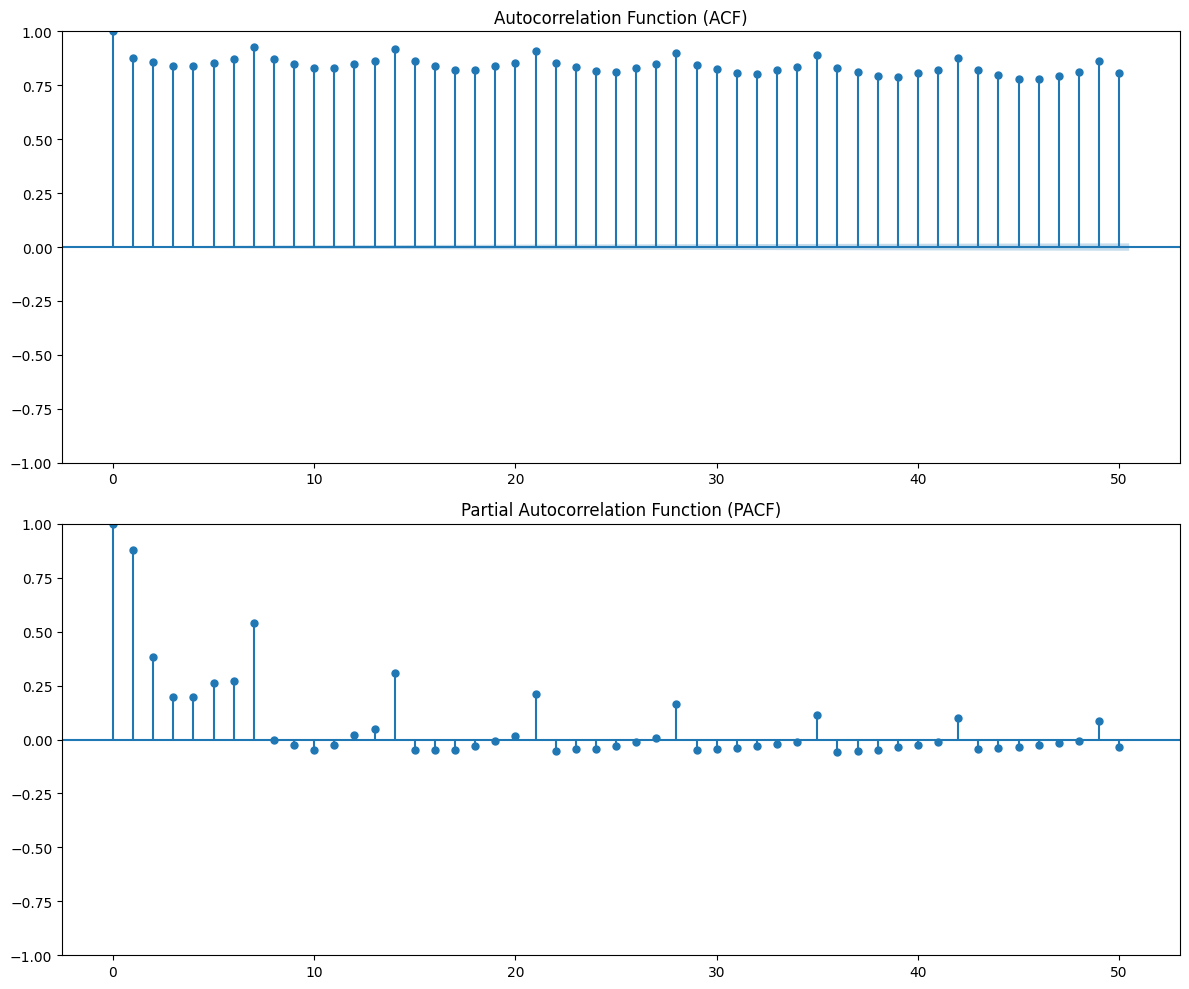

Running ADF Test with explicit maxlag=96
ADF Statistic: -32.8313153939581
p-value: 0.0
Critical Values:
   1%: -3.4303571632127263
   5%: -2.8615431660588673
   10%: -2.566771685176932
Result: Series is Stationary (reject H0)
(np.float64(-32.8313153939581), 0.0, 96, 912903, {'1%': np.float64(-3.4303571632127263), '5%': np.float64(-2.8615431660588673), '10%': np.float64(-2.566771685176932)})


In [ ]:
print("\n--- ACF and PACF Plots for Daily Quantity Sold ---")
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

plot_acf(df['sales'], lags=50, ax=axes[0], title='Autocorrelation Function (ACF)')
plot_pacf(df['sales'], lags=50, ax=axes[1], title='Partial Autocorrelation Function (PACF)')
plt.tight_layout()
plt.show()


print(adf_test(df['sales'], max_lag_val=try_maxlag))


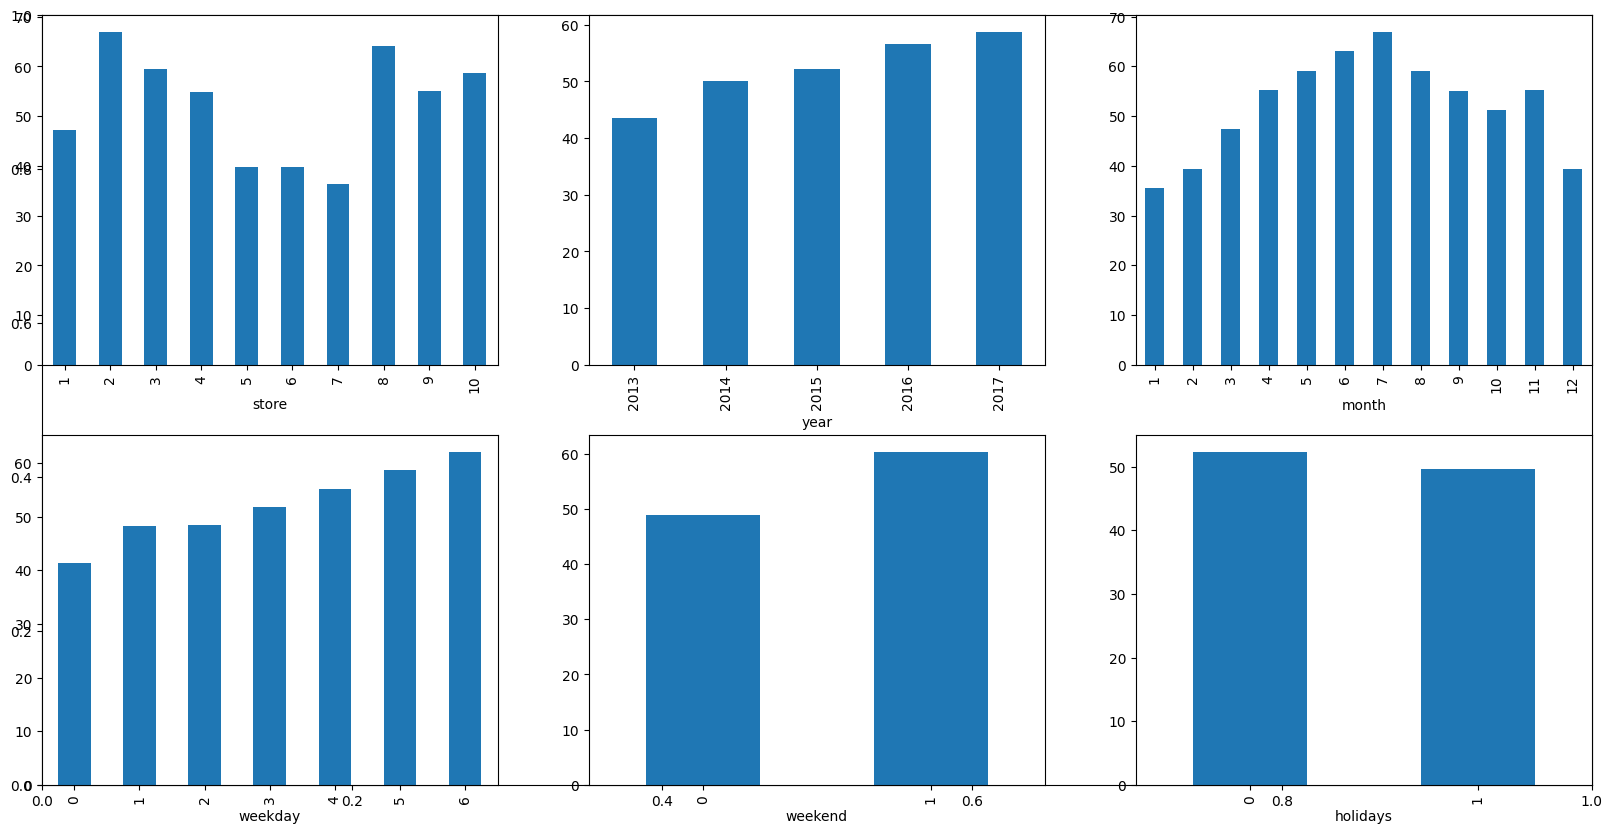

In [ ]:
df['weekend'] = df['weekday'].apply(lambda x: 1 if x >= 5 else 0)
features = ['store', 'year', 'month', 'weekday', 'weekend', 'holidays']

plt.subplots(figsize=(20, 10))
for i, col in enumerate(features):
    plt.subplot(2, 3, i + 1)
    df.groupby(col).mean()['sales'].plot.bar()
plt.show()

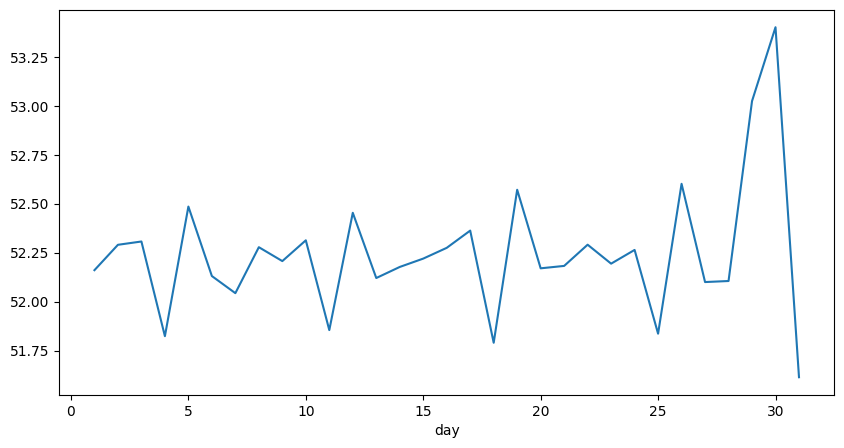

In [ ]:
plt.figure(figsize=(10,5))
df.groupby('day').mean()['sales'].plot()
plt.show()

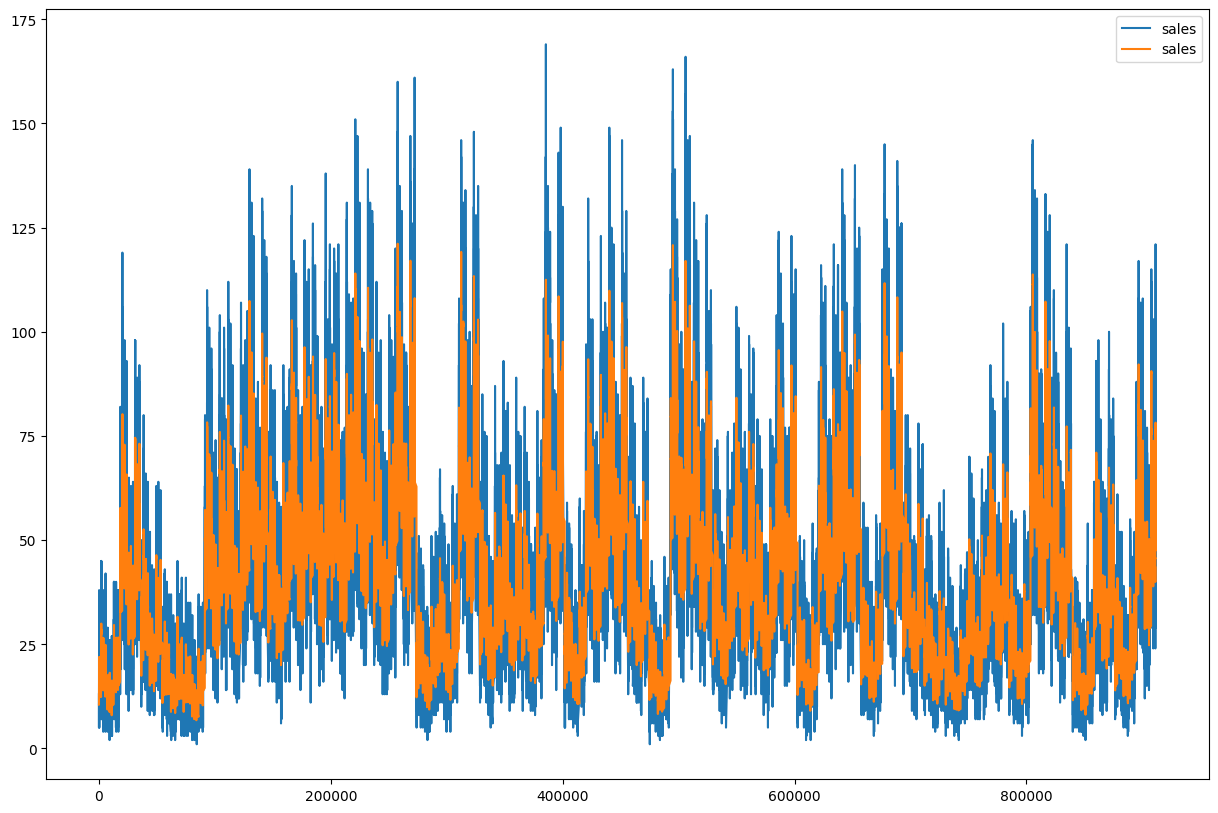

In [ ]:
plt.figure(figsize=(15, 10))

# Calculating Simple Moving Average
# for a window period of 30 days
window_size = 30
data = df[df['year']==2013]
windows = data['sales'].rolling(window_size)
sma = windows.mean()
sma = sma[window_size - 1:]

data['sales'].plot()
sma.plot()
plt.legend()
plt.show()

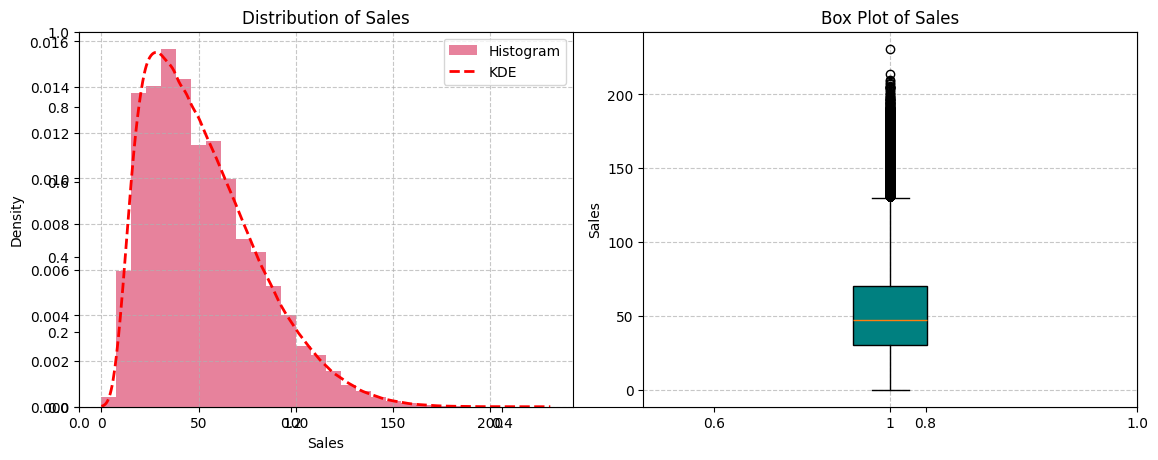

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde # For KDE


plt.subplots(figsize=(12, 5))

plt.subplot(1, 2, 1)

# 1. Histogram

plt.hist(df['sales'], bins=30, density=True, alpha=0.6, color="#D82F5A", label='Histogram')

# 2. Kernel Density Estimate (KDE)
# Calculate KDE
kde = gaussian_kde(df['sales'].dropna()) # .dropna() handles potential NaNs
# Create a range for the KDE plot
x_range = np.linspace(df['sales'].min(), df['sales'].max(), 500)
plt.plot(x_range, kde(x_range), color="red", linestyle='--', linewidth=2, label='KDE')

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Density")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)



plt.subplot(1, 2, 2)
plt.boxplot(df['sales'], vert=True, patch_artist=True, boxprops=dict(facecolor="#008080"))

plt.title("Box Plot of Sales")
plt.xlabel("") # Box plots typically don't need an x-label for single variable
plt.ylabel("Sales")
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout() # Adjusts subplot params for a tight layout
plt.show()

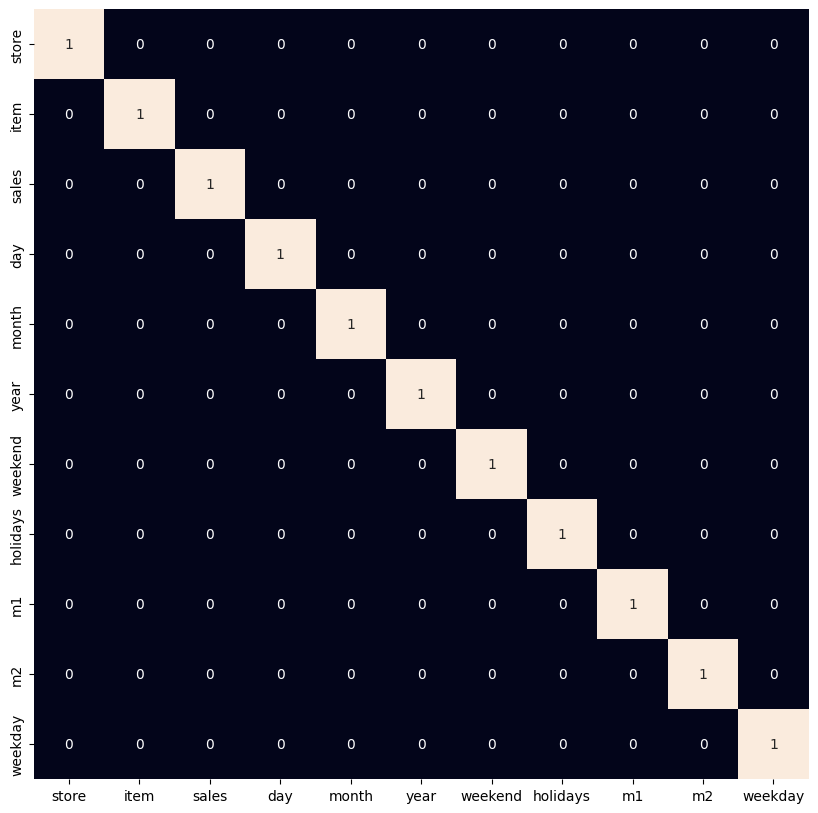

In [ ]:
plt.figure(figsize=(10, 10))
sns.heatmap(df.corr() > 0.8,
           annot=True,
           cbar=False)
plt.show()

In [ ]:
df = df[df['sales']<140]

In [ ]:
df.head()

,date,store,item,sales,day,month,year,weekend,holidays,m1,m2,weekday
0,01-01-2013,1,1,13,1,1,2013,0,0,0.5,0.866025,1
1,02-01-2013,1,1,11,2,1,2013,0,0,0.5,0.866025,2
2,03-01-2013,1,1,14,3,1,2013,0,0,0.5,0.866025,3
3,04-01-2013,1,1,13,4,1,2013,0,0,0.5,0.866025,4
4,05-01-2013,1,1,10,5,1,2013,1,0,0.5,0.866025,5


from matplotlib import pyplot as plt
_df_0['sales'].plot(kind='hist', bins=20, title='sales')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_1['day'].plot(kind='hist', bins=20, title='day')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_2['weekend'].plot(kind='hist', bins=20, title='weekend')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_3['weekday'].plot(kind='hist', bins=20, title='weekday')
plt.gca().spines[['top', 'right',]].set_visible(False)

...

from matplotlib import pyplot as plt
_df_15['weekday'].plot(kind='line', figsize=(8, 4), title='weekday')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(_df_16['date'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(_df_16, x='sales', y='date', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(_df_17['date'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(_df_17, x='day', y='date', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(_df_18['date'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(_df_18, x='weekend', y='date', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(_df_19['date'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(_df_19, x='weekday', y='date', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

In [ ]:
import pandas as pd
from statsmodels.tsa.stattools import grangercausalitytests
df_n = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/train.csv")
# Make sure your data frame has a datetime index, or a datetime column


In [ ]:
df_n.head()

,date,store,item,sales
0,01-01-2013,1,1,13
1,02-01-2013,1,1,11
2,03-01-2013,1,1,14
3,04-01-2013,1,1,13
4,05-01-2013,1,1,10


In [ ]:
df_n.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   date    913000 non-null  object
 1   store   913000 non-null  int64 
 2   item    913000 non-null  int64 
 3   sales   913000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 27.9+ MB


In [ ]:
df_n['Date'] = pd.to_datetime(df_n['date'], dayfirst=True)
df_n = df_n.set_index('Date')

# Aggregate sales per store
sales_per_store = df_n.groupby(['Date', 'store'])['sales'].sum().unstack().fillna(0)

# Example: Test if sales in Store 1 Granger-causes sales in Store 2
data = sales_per_store[[1, 2]]

# Run Granger causality test
maxlag = 7  # test lag from 1 to 7 days
results = grangercausalitytests(data, maxlag=maxlag, verbose=True)



Granger Causality
number of lags (no zero) 1
ssr based F test:         F=5.9877  , p=0.0145  , df_denom=1822, df_num=1
ssr based chi2 test:   chi2=5.9976  , p=0.0143  , df=1
likelihood ratio test: chi2=5.9878  , p=0.0144  , df=1
parameter F test:         F=5.9877  , p=0.0145  , df_denom=1822, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=4.9847  , p=0.0069  , df_denom=1819, df_num=2
ssr based chi2 test:   chi2=9.9968  , p=0.0067  , df=2
likelihood ratio test: chi2=9.9695  , p=0.0068  , df=2
parameter F test:         F=4.9847  , p=0.0069  , df_denom=1819, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=3.0557  , p=0.0274  , df_denom=1816, df_num=3
ssr based chi2 test:   chi2=9.2024  , p=0.0267  , df=3
likelihood ratio test: chi2=9.1793  , p=0.0270  , df=3
parameter F test:         F=3.0557  , p=0.0274  , df_denom=1816, df_num=3

Granger Causality
number of lags (no zero) 4
ssr based F test:         F=2.5730  , p=0.

# Granger Causality Test Interpretation

The Granger causality test was performed to determine if one time series has predictive power over another. The results for lags from 1 to 7 are summarized below:

| Number of Lags | F-Test Statistic | p-Value | Interpretation                         |
|----------------|------------------|---------|--------------------------------------|
| 1              | 5.9877           | 0.0145  | Significant causality (p < 0.05)     |
| 2              | 4.9847           | 0.0069  | Significant causality (p < 0.01)     |
| 3              | 3.0557           | 0.0274  | Significant causality (p < 0.05)     |
| 4              | 2.5730           | 0.0361  | Significant causality (p < 0.05)     |
| 5              | 4.0380           | 0.0012  | Significant causality (p < 0.01)     |
| 6              | 2.7627           | 0.0112  | Significant causality (p < 0.05)     |
| 7              | 11.9709          | 0.0000  | Highly significant causality (p ~ 0) |

**Key Takeaways:**

- The tested variable Granger-causes the target variable at all lags from 1 to 7 days.
- The p-values are all below the 0.05 significance threshold, providing strong evidence of predictive causality.
- This implies including lagged terms (up to 7 days) of this variable can improve forecasting models.
- Note: Granger causality indicates predictive causality, not true cause-effect relationships.


In [ ]:

# Create weekend indicator: 1 if Saturday or Sunday, else 0
df_n['weekend'] = df_n.index.weekday.map(lambda x: 1 if x >= 5 else 0)

# Prepare DataFrame with sales and weekend columns
# We need these as time series aligned by date
data = df_n[['sales', 'weekend']]

# Ensure data is sorted by date
data = data.sort_index()

# Granger causality test expects no missing values
data = data.dropna()

# Max lag (days) to test
maxlag = 7

print("Testing if 'weekend' Granger-causes 'sales'")
grangercausalitytests(data[['sales', 'weekend']], maxlag=maxlag, verbose=True)

print("\nTesting if 'sales' Granger-causes 'weekend'")
grangercausalitytests(data[['weekend', 'sales']], maxlag=maxlag, verbose=True)


Testing if 'weekend' Granger-causes 'sales'

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=20662.6050, p=0.0000  , df_denom=912996, df_num=1
ssr based chi2 test:   chi2=20662.6729, p=0.0000  , df=1
likelihood ratio test: chi2=20432.3267, p=0.0000  , df=1
parameter F test:         F=20662.6050, p=0.0000  , df_denom=912996, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=7544.3517, p=0.0000  , df_denom=912993, df_num=2
ssr based chi2 test:   chi2=15088.7860, p=0.0000  , df=2
likelihood ratio test: chi2=14965.4594, p=0.0000  , df=2
parameter F test:         F=7544.3517, p=0.0000  , df_denom=912993, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=3834.0315, p=0.0000  , df_denom=912990, df_num=3
ssr based chi2 test:   chi2=11502.1826, p=0.0000  , df=3
likelihood ratio test: chi2=11430.3317, p=0.0000  , df=3
parameter F test:         F=3834.0315, p=0.0000  , df_denom=912990, df_num=3

Granger Cau

{np.int64(1): ({'ssr_ftest': (np.float64(4.439251180287049),
    np.float64(0.035121920995241945),
    np.float64(912996.0),
    np.int64(1)),
   'ssr_chi2test': (np.float64(4.439265767156588),
    np.float64(0.03512134885815734),
    np.int64(1)),
   'lrtest': (np.float64(4.439255340024829),
    np.float64(0.03512156336760674),
    np.int64(1)),
   'params_ftest': (np.float64(4.439251544843214),
    np.float64(0.035121913495792065),
    np.float64(912996.0),
    1.0)},
   array([[0., 1., 0.]])]),
 np.int64(2): ({'ssr_ftest': (np.float64(2.647698740351329),
    np.float64(0.0708145308174625),
    np.float64(912993.0),
    np.int64(2)),
   'ssr_chi2test': (np.float64(5.295426480911207),
    np.float64(0.07081296026421476),
    np.int64(2)),
   'lrtest': (np.float64(5.2954108929261565),
    np.float64(0.07081351218204857),
    np.int64(2)),
   'params_ftest': (np.float64(2.6476986243745),
    np.float64(0.07081453903275223),
    np.float64(912993.0),
    2.0)},
   array([[0., 0., 1., 0.,

# Granger Causality Test Interpretation: Weekend and Sales

## Testing if 'weekend' Granger-causes 'sales'

| Number of Lags | F-Test Statistic | p-Value  | Interpretation                         |
|----------------|------------------|----------|--------------------------------------|
| 1              | 20662.6050       | 0.0000   | Highly significant causality         |
| 2              | 7544.3517        | 0.0000   | Highly significant causality         |
| 3              | 3834.0315        | 0.0000   | Highly significant causality         |
| 4              | 2276.5790        | 0.0000   | Highly significant causality         |
| 5              | 1476.9641        | 0.0000   | Highly significant causality         |
| 6              | 1023.2933        | 0.0000   | Highly significant causality         |
| 7              | 741.1058         | 0.0000   | Highly significant causality         |

**Interpretation:**  
The weekend indicator strongly **Granger-causes sales** at all tested lags (1 to 7 days) with extremely low p-values. This means that information about whether a day is a weekend significantly improves the prediction of sales.

---

## Testing if 'sales' Granger-causes 'weekend'

| Number of Lags | F-Test Statistic | p-Value  | Interpretation                         |
|----------------|------------------|----------|--------------------------------------|
| 1              | 4.4393           | 0.0351   | Significant causality                 |
| 2              | 2.6477           | 0.0708   | No significant causality              |
| 3              | 2.7340           | 0.0420   | Significant causality                 |
| 4              | 2.0660           | 0.0824   | No significant causality              |
| 5              | 2.3108           | 0.0414   | Significant causality                 |
| 6              | 2.0634           | 0.0540   | Marginal causality                    |
| 7              | 1.8765           | 0.0689   | No significant causality              |

**Interpretation:**  
Sales Granger-cause the weekend indicator at some lags (1, 3, 5) but the evidence is weaker and less consistent compared to the other direction.

---

### Overall Conclusion

- **Weekend status is a strong predictor of sales** (significant causality at all tested lags).
- Including weekend/weekday features in forecasting models will likely improve sales predictions.
- The reverse effect (sales predicting weekend) is weaker and less consistent, which aligns with intuition.




In [ ]:
df['sales_lag_7'] = df["sales"].shift(7)
df['sales_lag_14'] = df["sales"].shift(14)

# Create rolling statistics features (7-day window)
df['rolling_mean_7'] = df["sales"].rolling(window=7).mean()
df['rolling_std_7'] = df["sales"].rolling(window=7).std()

# Drop the initial rows with NaN values introduced by the new features
df.dropna(inplace=True)

# Display the new DataFrame with the created features
print(df.head())


          date  store  item  sales  day  month  year  weekend  holidays   m1  \
14  15-01-2013      1     1      5   15      1  2013        0         0  0.5   
15  16-01-2013      1     1      7   16      1  2013        0         0  0.5   
16  17-01-2013      1     1     16   17      1  2013        0         0  0.5   
17  18-01-2013      1     1      7   18      1  2013        0         0  0.5   
18  19-01-2013      1     1     18   19      1  2013        1         0  0.5   

          m2  weekday  sales_lag_7  sales_lag_14  rolling_mean_7  \
14  0.866025        1          9.0          13.0        9.142857   
15  0.866025        2         12.0          11.0        8.428571   
16  0.866025        3          9.0          14.0        9.428571   
17  0.866025        4          9.0          13.0        9.142857   
18  0.866025        5          7.0          10.0       10.714286   

    rolling_std_7  
14       2.544836  
15       2.299068  
16       3.690399  
17       3.804759  
18       4

In [ ]:
df['date'] = pd.to_datetime(df['date'], dayfirst=True)

In [ ]:
df = df.sort_values('date')

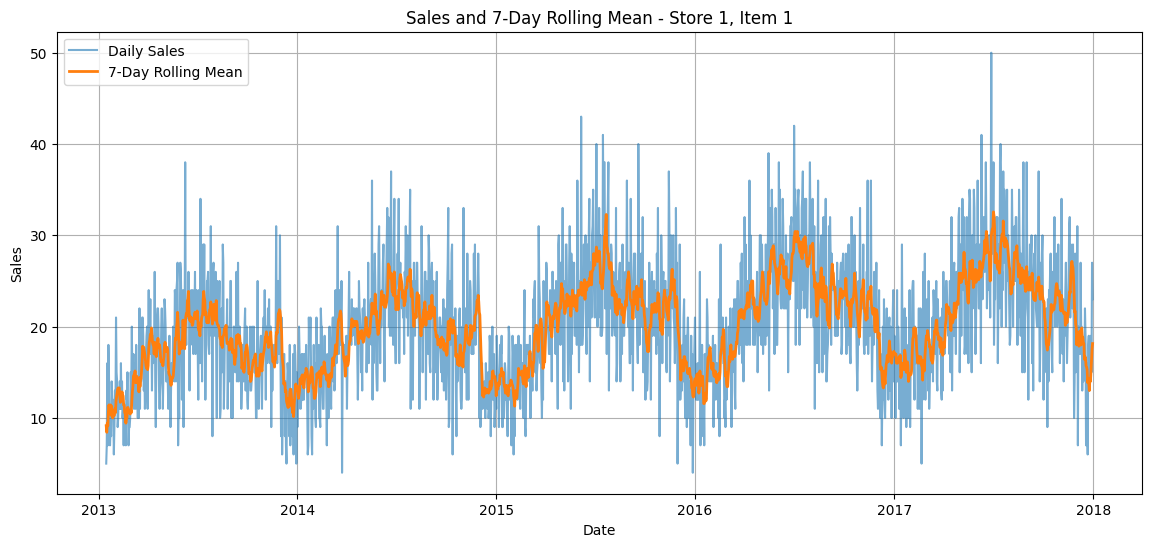

In [ ]:
# --- 1. Visualize Sales and Rolling Mean for a selected store-item pair ---
store_id = 1
item_id = 1
subset = df[(df['store'] == store_id) & (df['item'] == item_id)]

plt.figure(figsize=(14, 6))
plt.plot(subset['date'], subset['sales'], label='Daily Sales', alpha=0.6)
plt.plot(subset['date'], subset['rolling_mean_7'], label='7-Day Rolling Mean', linewidth=2)
plt.title(f'Sales and 7-Day Rolling Mean - Store {store_id}, Item {item_id}')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()


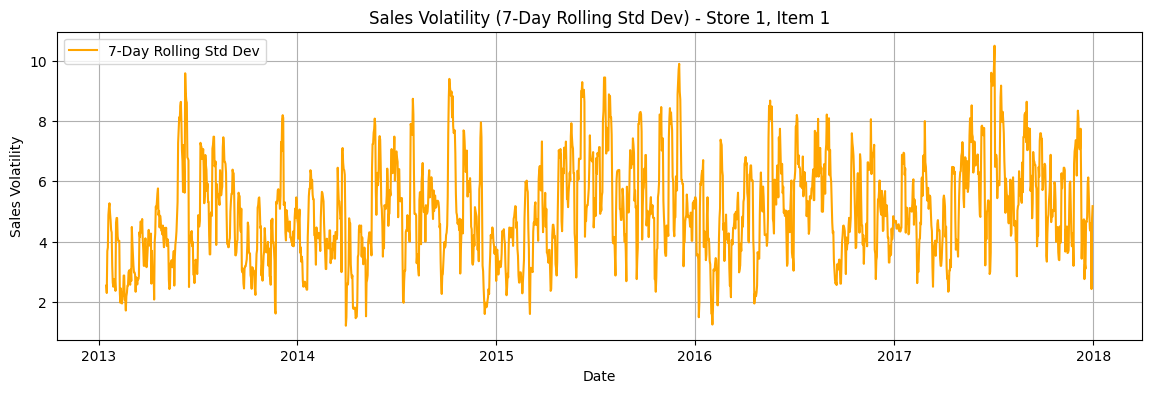

In [ ]:
# --- 2. Visualize Rolling Std Dev to Analyze Volatility ---
plt.figure(figsize=(14, 4))
plt.plot(subset['date'], subset['rolling_std_7'], label='7-Day Rolling Std Dev', color='orange')
plt.title(f'Sales Volatility (7-Day Rolling Std Dev) - Store {store_id}, Item {item_id}')
plt.xlabel('Date')
plt.ylabel('Sales Volatility')
plt.legend()
plt.grid(True)
plt.show()


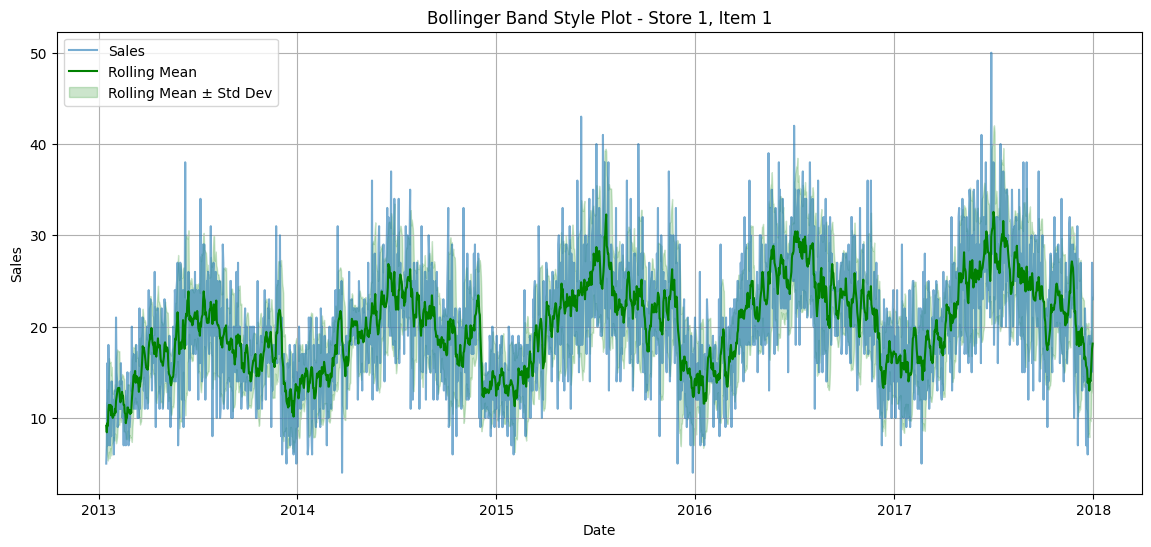

In [ ]:
# --- 3. Plot Bollinger Band Style Visualization ---
plt.figure(figsize=(14, 6))
plt.plot(subset['date'], subset['sales'], label='Sales', alpha=0.6)
plt.plot(subset['date'], subset['rolling_mean_7'], label='Rolling Mean', color='green')
plt.fill_between(
    subset['date'],
    subset['rolling_mean_7'] - subset['rolling_std_7'],
    subset['rolling_mean_7'] + subset['rolling_std_7'],
    color='green',
    alpha=0.2,
    label='Rolling Mean ± Std Dev'
)
plt.title(f'Bollinger Band Style Plot - Store {store_id}, Item {item_id}')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# --- 4. Flagging Outliers based on rolling std ---
df['is_outlier'] = np.abs(df['sales'] - df['rolling_mean_7']) > 2 * df['rolling_std_7']

# Display some outlier days
outliers = df[df['is_outlier']]
print(f'Number of outliers detected: {len(outliers)}')

Number of outliers detected: 7153


In [ ]:
# --- 5. Correlation analysis ---
corr_rolling_mean = df['sales'].corr(df['rolling_mean_7'])
corr_rolling_std = df['sales'].corr(df['rolling_std_7'])
print(f"Correlation between sales and rolling mean: {corr_rolling_mean:.3f}")
print(f"Correlation between sales and rolling std dev: {corr_rolling_std:.3f}")

Correlation between sales and rolling mean: 0.935
Correlation between sales and rolling std dev: 0.733


In [ ]:
# --- 6. Grouped Analysis: Summary of volatility and trend per store-item ---
grouped_summary = df.groupby(['store', 'item']).agg(
    mean_sales=('sales', 'mean'),
    mean_rolling_mean_7=('rolling_mean_7', 'mean'),
    mean_rolling_std_7=('rolling_std_7', 'mean'),
    outlier_days=('is_outlier', 'sum')
).reset_index()

print(grouped_summary.head())


   store  item  mean_sales  mean_rolling_mean_7  mean_rolling_std_7  \
0      1     1   20.042494            20.024598            5.029132   
1      1     2   53.148959            53.093334            9.912830   
2      1     3   33.208105            33.248005            7.105489   
3      1     4   19.956188            19.984588            5.110769   
4      1     5   16.612815            16.625567            4.377782   

   outlier_days  
0            17  
1            13  
2            18  
3            21  
4            16  


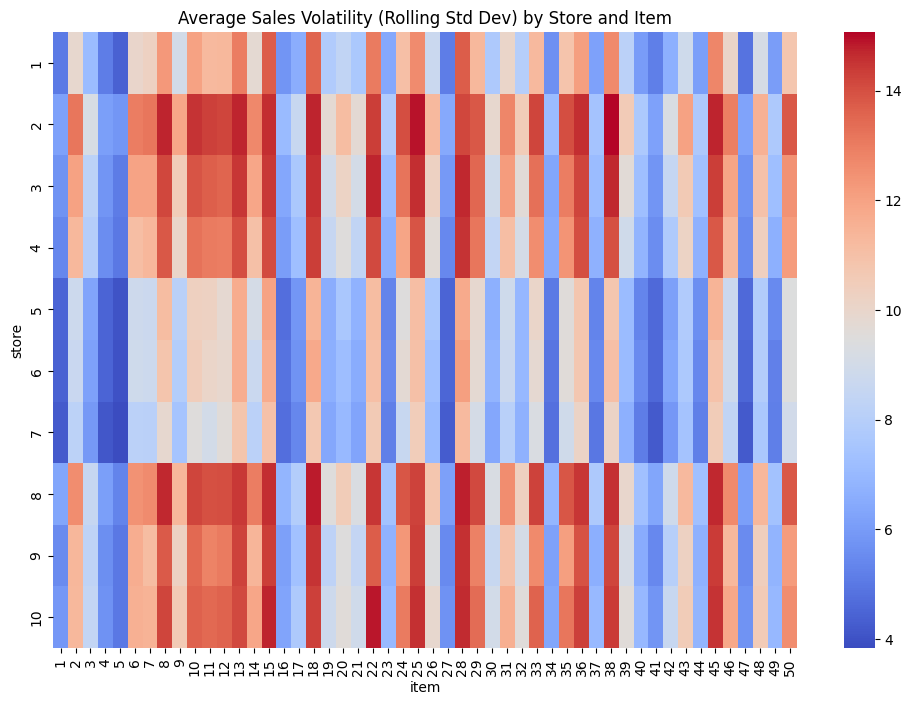

In [ ]:
# 7.heatmap of volatility by store and item
pivot_volatility = grouped_summary.pivot(index='store', columns='item', values='mean_rolling_std_7')
plt.figure(figsize=(12, 8))
sns.heatmap(pivot_volatility, annot=False, fmt=".1f", cmap='coolwarm')
plt.title('Average Sales Volatility (Rolling Std Dev) by Store and Item')
plt.show()

### Sales Trend and Volatility Analysis Using Rolling Statistics

#### 1. Visualize Trend and Seasonality

- Plot the original **daily sales** alongside the **7-day rolling mean** (`rolling_mean_7`) to smooth out noise and reveal long-term trends.
- Compare the 7-day rolling mean with a longer window (e.g., 30-day rolling mean) to understand short-term vs. long-term trends.
- **Insight:** Large differences between short-term and long-term rolling means indicate recent changes such as promotions or seasonal effects.

#### 2. Analyze Volatility and Consistency

- Plot the **7-day rolling standard deviation** (`rolling_std_7`) over time to highlight periods of high or low sales volatility.
- Combine sales, rolling mean, and a band defined by `rolling_mean_7 ± rolling_std_7` (similar to Bollinger Bands) to visualize consistency and anomalies.
- **Insight:** High volatility may signal irregular demand or external impacts; low volatility indicates stable sales patterns.

#### 3. Identify and Investigate Outliers

- Flag outliers where sales deviate by more than 2 standard deviations from the rolling mean: `is_outlier = |sales - rolling_mean_7| > 2 * rolling_std_7`


- **Insight:** These outliers could be due to special events, errors or unusual demand spikes/dips worth further examination.

#### 4. Correlation Analysis

- Calculate correlations between sales and the rolling statistics (`rolling_mean_7`, `rolling_std_7`).

- **Insight:**  
- High correlation between sales and rolling mean confirms the rolling mean captures the sales trend well.  
- Positive correlation with rolling std indicates that rising volatility in sales is reflected by rolling statistics.

#### 5. Grouped Analysis by Store and Item

- Perform all analyses above at the granularity of **each store-item pair** to identify specific patterns.

- **Insight:**  
- Pinpoint which stores or items have more volatile sales or unique trend behaviors.  
- Tailor inventory and marketing strategies accordingly.

#### 6. Heatmap

This heatmap visualizes the average sales volatility, measured as the 7-day rolling standard deviation, for each combination of store (rows) and item (columns).

##### Color Scale:
- **Darker red** indicates higher volatility, meaning greater day-to-day fluctuations in sales.
- **Darker blue** indicates lower volatility, representing more consistent and stable sales.

##### Horizontal Patterns (by Item):
- Certain items (e.g., items around 10–20 ) show more red, implying these items are volatile across many or all stores. This may be due to irregular demand, promotions, or seasonality.
- Items with more blue are steadier across stores, suggesting routine and predictable demand.

##### Vertical Patterns (by Store):
- Stores with predominately red or blue across many items indicate overall higher or lower volatility, possibly related to their customer base, location, or management style.

##### Mixed Patterns:
- Some store–item pairs stand out as especially red or blue relative to the rest of their row or column, highlighting outlier products or stores that may need specific managerial attention.

##### Business Actions:
- **High volatility (red)** items or stores might warrant improved forecasting methods, larger stock buffers, or investigation into causes such as promotions, local events, or supply chain issues.
- **Stable (blue)** items or stores suggest potential for just-in-time inventory management and risk reduction.



In [ ]:
df.head()

,date,store,item,sales,day,month,year,weekend,holidays,m1,m2,weekday,sales_lag_7,sales_lag_14,rolling_mean_7,rolling_std_7
14,15-01-2013,1,1,5,15,1,2013,0,0,0.5,0.866025,1,9.0,13.0,9.142857,2.544836
15,16-01-2013,1,1,7,16,1,2013,0,0,0.5,0.866025,2,12.0,11.0,8.428571,2.299068
16,17-01-2013,1,1,16,17,1,2013,0,0,0.5,0.866025,3,9.0,14.0,9.428571,3.690399
17,18-01-2013,1,1,7,18,1,2013,0,0,0.5,0.866025,4,9.0,13.0,9.142857,3.804759
18,19-01-2013,1,1,18,19,1,2013,1,0,0.5,0.866025,5,7.0,10.0,10.714286,4.889250


In [ ]:
features = df.drop(['sales', 'year','date'], axis=1)
target = df['sales'].values


X_train, X_val, Y_train, Y_val = train_test_split(features, target,
                                                  test_size = 0.05,
                                                  random_state=22)
X_train.shape, X_val.shape

((867336, 13), (45650, 13))

In [ ]:
from sklearn.metrics import r2_score
# Define models with GPU support enabled for XGBoost models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.1),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting Regressor': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'XGBoost Regressor': xgb.XGBRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        eval_metric='rmse',
        tree_method='gpu_hist',          # Enable GPU training
        predictor='gpu_predictor'        # Enable GPU prediction
    ),
    'XGBoost without any specific Parameters': xgb.XGBRegressor(
        tree_method='gpu_hist',
        predictor='gpu_predictor'
    )
}


# Prepare features and target
features = df.drop(['sales', 'year', 'date'], axis=1)
target = df['sales'].values


# Time-based split
train_size = int(len(df) * 0.95)
X_train_time = features.iloc[:train_size]
Y_train_time = target[:train_size]
X_val_time = features.iloc[train_size:]
Y_val_time = target[train_size:]


# Random split
X_train_rand, X_val_rand, Y_train_rand, Y_val_rand = train_test_split(features, target, test_size=0.05, random_state=22)


# Collect model metrics
results = []


for model_name, model in models.items():


    # Time-based split
    model.fit(X_train_time, Y_train_time)
    train_preds_time = model.predict(X_train_time)
    val_preds_time = model.predict(X_val_time)
    train_mae_time = mae(Y_train_time, train_preds_time)
    train_rmse_time = np.sqrt(mse(Y_train_time, train_preds_time))
    train_r2_time = r2_score(Y_train_time, train_preds_time)
    val_mae_time = mae(Y_val_time, val_preds_time)
    val_rmse_time = np.sqrt(mse(Y_val_time, val_preds_time))
    val_r2_time = r2_score(Y_val_time, val_preds_time)


    # Random split
    model.fit(X_train_rand, Y_train_rand)
    train_preds_rand = model.predict(X_train_rand)
    val_preds_rand = model.predict(X_val_rand)
    train_mae_rand = mae(Y_train_rand, train_preds_rand)
    train_rmse_rand = np.sqrt(mse(Y_train_rand, train_preds_rand))
    train_r2_rand = r2_score(Y_train_rand, train_preds_rand)
    val_mae_rand = mae(Y_val_rand, val_preds_rand)
    val_rmse_rand = np.sqrt(mse(Y_val_rand, val_preds_rand))
    val_r2_rand = r2_score(Y_val_rand, val_preds_rand)


    # Append results for time-based split
    results.append({
        'Model': model_name,
        'Split': 'Time-based',
        'Train MAE': train_mae_time,
        'Train RMSE': train_rmse_time,
        'Train R2': train_r2_time,
        'Val MAE': val_mae_time,
        'Val RMSE': val_rmse_time,
        'Val R2': val_r2_time
    })


    # Append results for random split
    results.append({
        'Model': model_name,
        'Split': 'Random',
        'Train MAE': train_mae_rand,
        'Train RMSE': train_rmse_rand,
        'Train R2': train_r2_rand,
        'Val MAE': val_mae_rand,
        'Val RMSE': val_rmse_rand,
        'Val R2': val_r2_rand
    })


    print(f"{model_name} - Time-based split: Val MAE={val_mae_time:.3f}, RMSE={val_rmse_time:.3f}, R2={val_r2_time:.3f}")
    print(f"{model_name} - Random split: Val MAE={val_mae_rand:.3f}, RMSE={val_rmse_rand:.3f}, R2={val_r2_rand:.3f}")




Linear Regression - Time-based split: Val MAE=5.587, RMSE=7.172, R2=0.911
Linear Regression - Random split: Val MAE=5.902, RMSE=7.652, R2=0.930
Ridge Regression - Time-based split: Val MAE=5.587, RMSE=7.172, R2=0.911
Ridge Regression - Random split: Val MAE=5.902, RMSE=7.652, R2=0.930
Lasso Regression - Time-based split: Val MAE=5.584, RMSE=7.174, R2=0.911
Lasso Regression - Random split: Val MAE=5.904, RMSE=7.659, R2=0.930
Random Forest Regressor - Time-based split: Val MAE=4.893, RMSE=6.316, R2=0.931
Random Forest Regressor - Random split: Val MAE=5.035, RMSE=6.536, R2=0.949
Gradient Boosting Regressor - Time-based split: Val MAE=4.970, RMSE=6.398, R2=0.929
Gradient Boosting Regressor - Random split: Val MAE=5.159, RMSE=6.673, R2=0.947
XGBoost Regressor - Time-based split: Val MAE=4.722, RMSE=6.098, R2=0.936
XGBoost Regressor - Random split: Val MAE=4.892, RMSE=6.334, R2=0.952
XGBoost without any specific Parameters - Time-based split: Val MAE=4.722, RMSE=6.098, R2=0.936
XGBoost with

In [ ]:

# Create DataFrame with all results
results_df = pd.DataFrame(results)
print("\nSummary of model performance:")
print(results_df)



Summary of model performance:
                                      Model       Split  Train MAE  \
0                         Linear Regression  Time-based   5.913705   
1                         Linear Regression      Random   5.895440   
2                          Ridge Regression  Time-based   5.913704   
3                          Ridge Regression      Random   5.895440   
4                          Lasso Regression  Time-based   5.913969   
5                          Lasso Regression      Random   5.895686   
6                   Random Forest Regressor  Time-based   1.875097   
7                   Random Forest Regressor      Random   1.872630   
8               Gradient Boosting Regressor  Time-based   5.170777   
9               Gradient Boosting Regressor      Random   5.152061   
10                        XGBoost Regressor  Time-based   4.855228   
11                        XGBoost Regressor      Random   4.844373   
12  XGBoost without any specific Parameters  Time-based   4

Best model for Time-based split: XGBoost without any specific Parameters with Val RMSE=6.098
Best model for Random split: XGBoost without any specific Parameters with Val RMSE=6.334


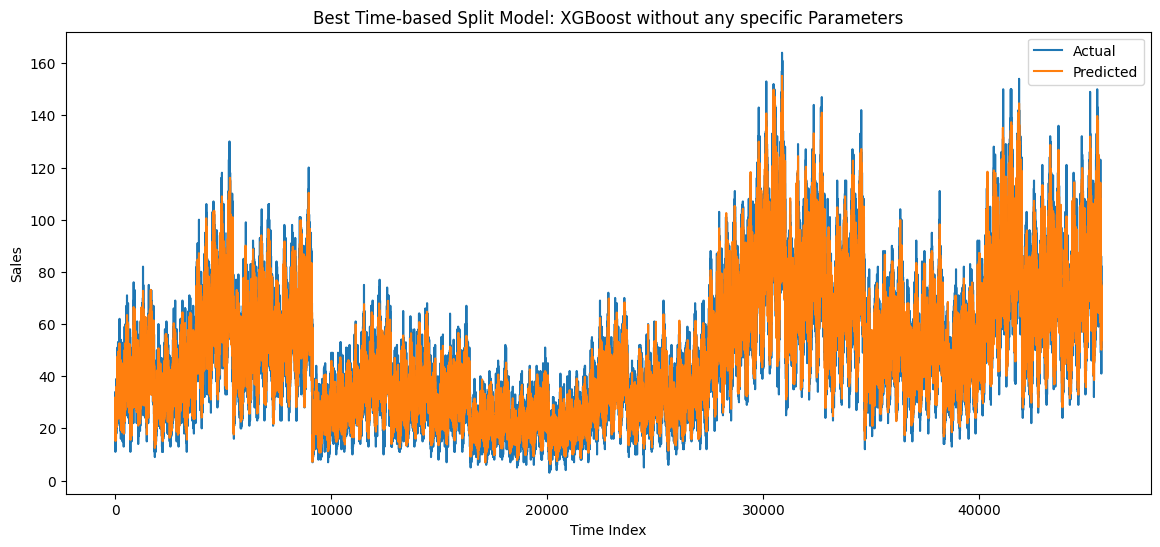

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# After your existing training loop, create a DataFrame with results
results_df = pd.DataFrame(results)

# Find best model by validation RMSE for each split
best_time_model = results_df[results_df['Split'] == 'Time-based'].sort_values('Val RMSE').iloc[0]
best_rand_model = results_df[results_df['Split'] == 'Random'].sort_values('Val RMSE').iloc[0]

print(f"Best model for Time-based split: {best_time_model['Model']} with Val RMSE={best_time_model['Val RMSE']:.3f}")
print(f"Best model for Random split: {best_rand_model['Model']} with Val RMSE={best_rand_model['Val RMSE']:.3f}")

# Retrieve best model objects again (assuming 'models' dict exists)
best_time_model_obj = models[best_time_model['Model']]
best_rand_model_obj = models[best_rand_model['Model']]

# Refit best models on training data
best_time_model_obj.fit(X_train_time, Y_train_time)
best_rand_model_obj.fit(X_train_rand, Y_train_rand)

# Predictions for validation sets
val_preds_time = best_time_model_obj.predict(X_val_time)
val_preds_rand = best_rand_model_obj.predict(X_val_rand)

# Plot actual vs predicted for both splits
plt.figure(figsize=(14, 6))

plt.plot(Y_val_time, label='Actual')
plt.plot(val_preds_time, label='Predicted')
plt.title(f"Best Time-based Split Model: {best_time_model['Model']}")
plt.xlabel('Time Index')
plt.ylabel('Sales')
plt.legend()


plt.show()



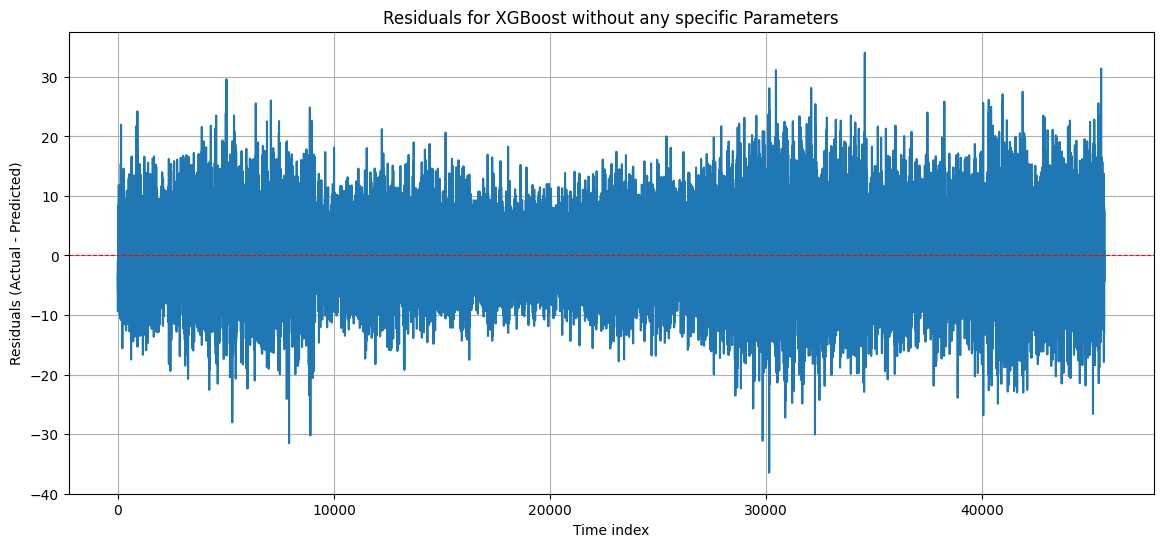

In [ ]:


# Plot residuals
residuals = Y_val_time - val_preds_time
plt.figure(figsize=(14, 6))
plt.plot(residuals, label='Residuals')
plt.title(f'Residuals for {best_time_model['Model']}')
plt.xlabel('Time index')
plt.ylabel('Residuals (Actual - Predicted)')
plt.axhline(0, color='red', linestyle='--', linewidth=0.8)
plt.grid(True)
plt.show()



In [ ]:
# ---  ARIMA Model Implementation ---

print("\n\n---  ARIMA Model Implementation ---")

# ARIMA (AutoRegressive Integrated Moving Average) Model parameters:
# p: Number of lag observations (AutoRegressive part)
# d: The degree of differencing (Integrated part)
# q: The size of the moving average window (Moving Average part)

time_series_arima = df['sales']

# Split data into training and testing sets for ARIMA.

train_size_arima = int(len(time_series_arima) * 0.95)
train_series_arima = time_series_arima[:train_size_arima]
test_series_arima = time_series_arima[train_size_arima:]

print(f"ARIMA Training series size: {len(train_series_arima)} samples")
print(f"ARIMA Testing series size: {len(test_series_arima)} samples")



---  ARIMA Model Implementation ---
ARIMA Training series size: 867350 samples
ARIMA Testing series size: 45650 samples



--- Determining 'd' parameter for ARIMA ---
Stationarity means statistical properties of the series (mean, variance, autocorrelation) do not change over time.
Most time series models, including ARIMA, assume stationarity.


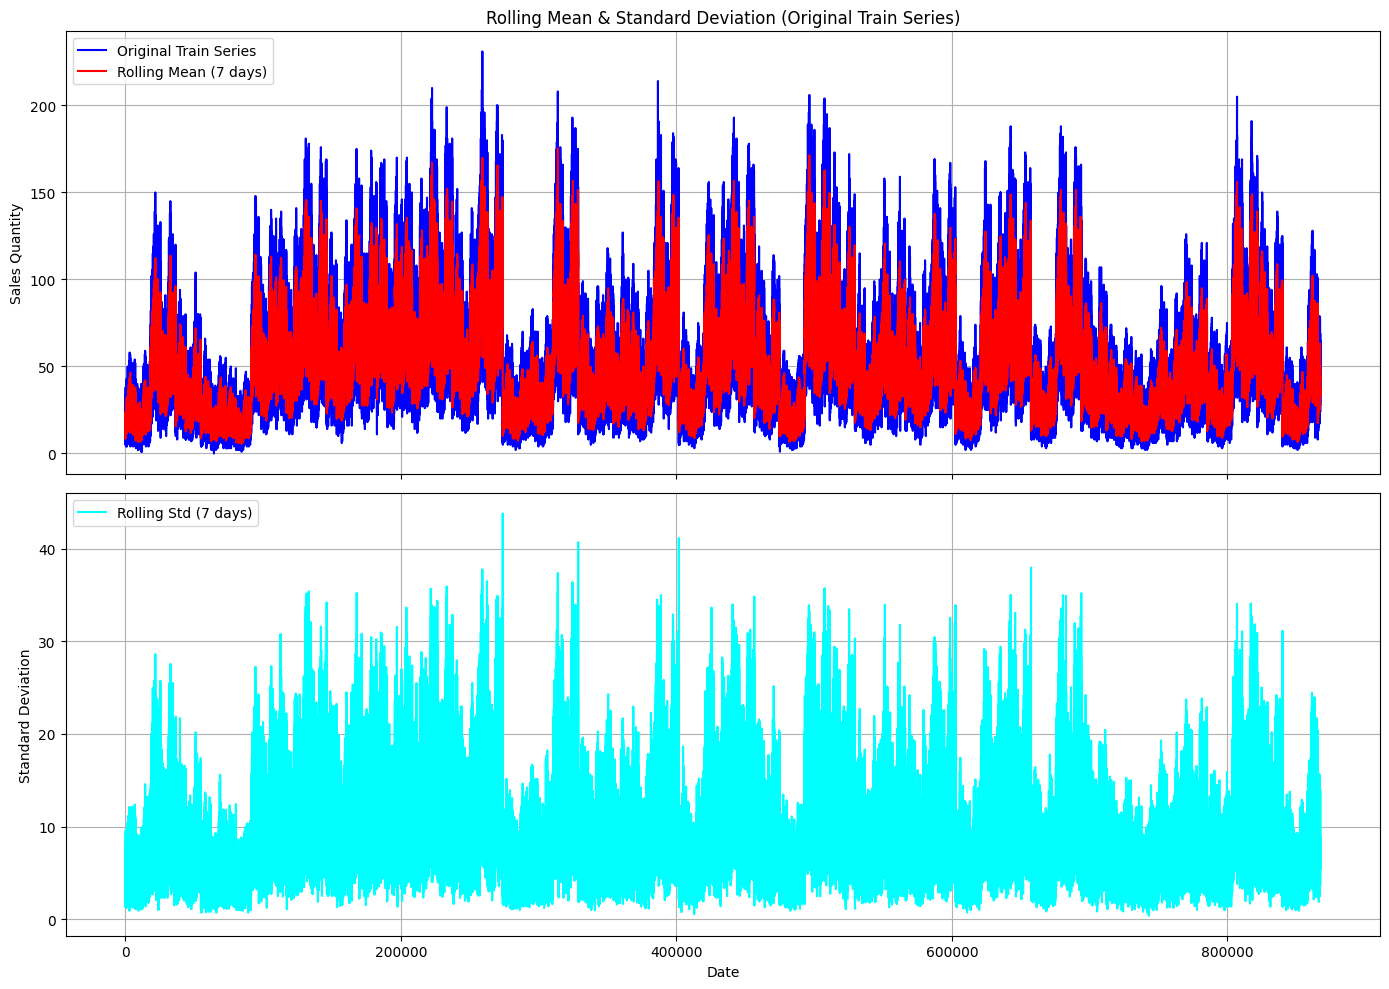

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


window = 7
rolmean = train_series_arima.rolling(window).mean()
rolstd = train_series_arima.rolling(window).std()

plt.rcParams['agg.path.chunksize'] = 10000 # Keep this to avoid OverflowError

print("\n--- Determining 'd' parameter for ARIMA ---")
print("Stationarity means statistical properties of the series (mean, variance, autocorrelation) do not change over time.")
print("Most time series models, including ARIMA, assume stationarity.")

# Create a figure with two subplots, sharing the x-axis
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Plot 1: Original Series and Rolling Mean (larger scale)
axes[0].plot(train_series_arima.index.to_numpy(), train_series_arima.to_numpy(), color='blue', label='Original Train Series')
axes[0].plot(rolmean.index.to_numpy(), rolmean.to_numpy(), color='red', label='Rolling Mean ({} days)'.format(window))
axes[0].set_title('Rolling Mean & Standard Deviation (Original Train Series)')
axes[0].set_ylabel('Sales Quantity')
axes[0].legend(loc='upper left')
axes[0].grid(True)

# Plot 2: Rolling Standard Deviation (its own smaller scale)
axes[1].plot(rolstd.index.to_numpy(), rolstd.to_numpy(), color='cyan', label = 'Rolling Std ({} days)'.format(window))
axes[1].set_ylabel('Standard Deviation')
axes[1].set_xlabel('Date') # Only label x-axis on the bottom subplot
axes[1].legend(loc='upper left')
axes[1].grid(True)

plt.tight_layout() # Adjusts plot to prevent labels/titles from overlapping
plt.show()


### Top Plot: Sales Time Series
- **Blue line:** Represents the original daily sales quantity over time.
- **Red overlay:** Shows the 7-day rolling mean, smoothing out daily fluctuations and highlighting weekly trends.
- The visual reveals clear recurring spikes and dips, indicating strong **seasonality** and possibly promotional or holiday effects.
- The overall level (mean) and amplitude (volatility) of sales appear to vary throughout the series, hinting at non-stationarity.

### Bottom Plot: Rolling Standard Deviation
- **Cyan line:** Shows the 7-day rolling standard deviation, quantifying the volatility or consistency in sales.
- High peaks in the rolling standard deviation correspond to periods of greater variability, possibly due to events, promotions, or holidays.
- Sustained periods of low standard deviation suggest stable sales and predictable demand.

## Insights for Time Series Modeling

- The time series displays **significant non-stationarity** in both mean and volatility, which is important for modeling (ARIMA and other models require stationary data).
- **Rolling mean** makes it easy to spot underlying trend changes and the effect of weekly cycles.
- **Rolling standard deviation** highlights varying sales risk and informs periods requiring special inventory or strategy attention.

## Recommended Actions

- **Differencing**, **log-transforming**, or **seasonal decomposition** may be needed before applying models like ARIMA.
- Focus on periods with high volatility for anomaly detection or special business interventions.


## Using ARIMA

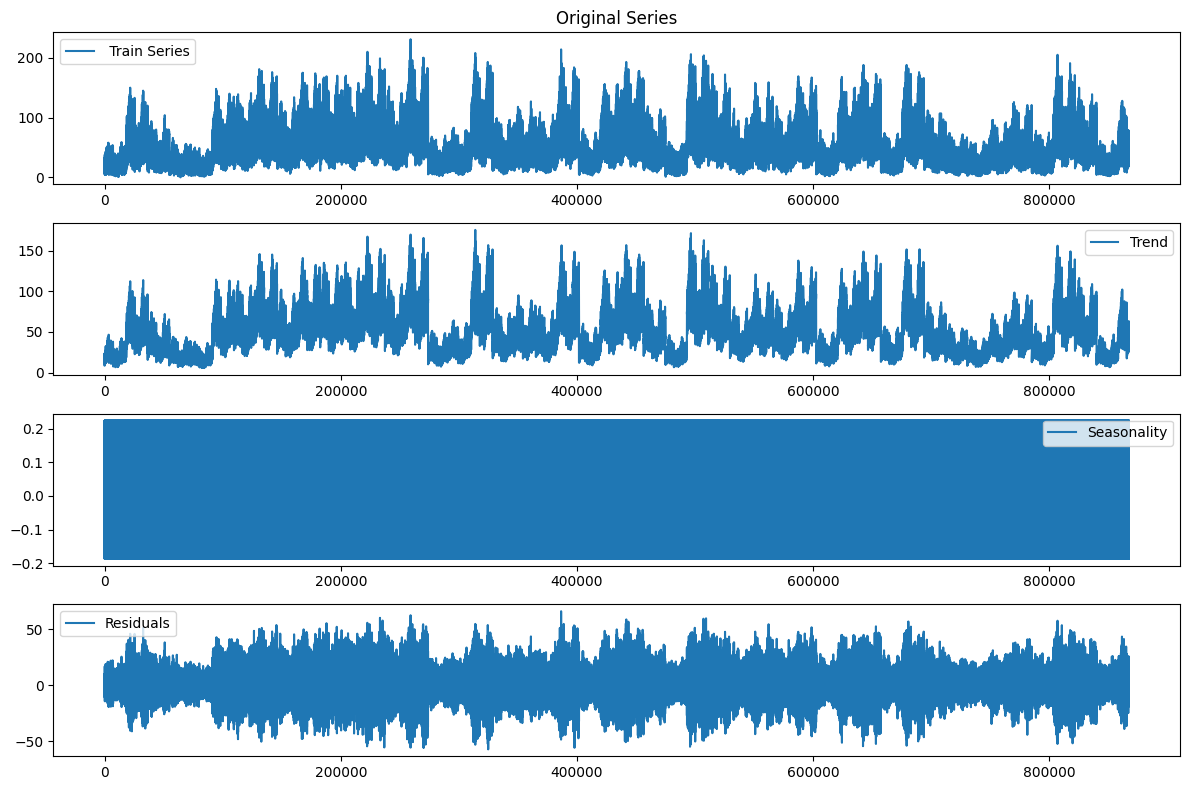

In [ ]:

from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(train_series_arima, model='additive', period=7)

# Extract the components
trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

# Plot the decomposition
plt.figure(figsize=(12,8))
plt.subplot(411)
plt.plot(train_series_arima, label=' Train Series')
plt.legend(loc='best')
plt.title('Original Series')

plt.subplot(412)
plt.plot(trend, label='Trend')
plt.legend(loc='best')

plt.subplot(413)
plt.plot(seasonal, label='Seasonality')
plt.legend(loc='best')

plt.subplot(414)
plt.plot(residual, label='Residuals')
plt.legend(loc='best')

plt.tight_layout()
plt.show()


Earlier seen the data is stationary as per ad fuller test

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/train.csv")

In [ ]:
df.head()

,date,store,item,sales
0,01-01-2013,1,1,13
1,02-01-2013,1,1,11
2,03-01-2013,1,1,14
3,04-01-2013,1,1,13
4,05-01-2013,1,1,10


In [ ]:
# Convert date column to datetime dtype
df['date'] = pd.to_datetime(df['date'], format='%d-%m-%Y')

# Set the date column as the index
df.set_index('date', inplace=True)

# Verify
print(df.index)
print(df.head())

DatetimeIndex(['2013-01-01', '2013-01-02', '2013-01-03', '2013-01-04',
               '2013-01-05', '2013-01-06', '2013-01-07', '2013-01-08',
               '2013-01-09', '2013-01-10',
               ...
               '2017-12-22', '2017-12-23', '2017-12-24', '2017-12-25',
               '2017-12-26', '2017-12-27', '2017-12-28', '2017-12-29',
               '2017-12-30', '2017-12-31'],
              dtype='datetime64[ns]', name='date', length=913000, freq=None)
            store  item  sales
date                          
2013-01-01      1     1     13
2013-01-02      1     1     11
2013-01-03      1     1     14
2013-01-04      1     1     13
2013-01-05      1     1     10


In [ ]:
print("\nInterpretation for p and q from differenced series plots:")
print("  - 'p' (AR order): Look at the PACF plot. The 'p' value is often the last significant lag (outside blue band).")
print("  - 'q' (MA order): Look at the ACF plot. The 'q' value is often the last significant lag (outside blue band).")
print("  Based on your provided guidance and typical interpretations, we will use:")
print("  p = 5 (from PACF after differencing, assuming 5 significant lags)")
print("  q = 0 (from ACF after differencing, assuming no significant moving average component after the first lag)")
print("  Therefore, the ARIMA order (p,d,q) = (5, 0, 0) will be used.")



Interpretation for p and q from differenced series plots:
  - 'p' (AR order): Look at the PACF plot. The 'p' value is often the last significant lag (outside blue band).
  - 'q' (MA order): Look at the ACF plot. The 'q' value is often the last significant lag (outside blue band).
  Based on your provided guidance and typical interpretations, we will use:
  p = 5 (from PACF after differencing, assuming 5 significant lags)
  q = 0 (from ACF after differencing, assuming no significant moving average component after the first lag)
  Therefore, the ARIMA order (p,d,q) = (5, 0, 0) will be used.


In [ ]:
# --- Evaluation Metrics for ARIMA ---
def smape_kun(y_true, y_pred):
    """
    Calculates the Symmetric Mean Absolute Percentage Error (SMAPE).
    This is a common accuracy measure for forecasting.
    """
    # Avoid division by zero by adding a small epsilon or checking for zero in denominator
    return np.mean(200 * np.abs(y_pred - y_true) / (np.abs(y_pred) + np.abs(y_true) + 1e-8))


In [ ]:
# --- Differencing the Test Series ---
print("\n--- Differencing the Test Series for ARIMA ---")
# Apply the same differencing to the test series for consistency in comparison
test_diff_arima = test_series_arima.diff().dropna()
print("First 5 rows of differenced testing series:")
print(test_diff_arima.head())


# --- Train and Forecast using ARIMA Model (Rolling Prediction) ---
print("\n--- Training and Forecasting with ARIMA (Rolling Prediction) ---")
print("Using a rolling forecast means the model is re-fitted as new actual observations become available.")
print("Note: The `statsmodels.tsa.arima_model.ARIMA` is a legacy class. For new projects, consider `statsmodels.tsa.statespace.sarimax.SARIMAX` for better seasonal handling and robustness.")



--- Differencing the Test Series for ARIMA ---
First 5 rows of differenced testing series:
867638   -8.0
867639    1.0
867640    8.0
867641    1.0
867642   -5.0
Name: sales, dtype: float64

--- Training and Forecasting with ARIMA (Rolling Prediction) ---
Using a rolling forecast means the model is re-fitted as new actual observations become available.
Note: The `statsmodels.tsa.arima_model.ARIMA` is a legacy class. For new projects, consider `statsmodels.tsa.statespace.sarimax.SARIMAX` for better seasonal handling and robustness.


In [ ]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

In [ ]:
if 'Date' not in df.columns or not pd.api.types.is_datetime64_any_dtype(df['Date']):
    print("\nCreating 'Date' column from 'year', 'month', 'day'...")
    try:
        # Use pd.to_datetime with a dictionary or list of columns
        df['Date'] = pd.to_datetime(df[['year', 'month', 'day']])
        print("'Date' column created successfully.")
    except Exception as e:
        print(f"Error creating 'Date' column: {e}.")
        print("Please ensure 'year', 'month', 'day' columns exist and contain valid numeric data.")
        # Handle the error, perhaps by exiting or using a different date parsing method
        exit() # Exit for demonstration if date creation fails
else:
    print("\n'Date' column already exists and is datetime type.")

print("\nDataFrame with 'Date' column head:\n", df.head())
print("\nDataFrame with 'Date' column info:")
df.info()


'Date' column already exists and is datetime type.

DataFrame with 'Date' column head:
    store  item  sales  day  month  year  weekend  holidays   m1        m2  \
0      1     1     13    1      1  2013        0         0  0.5  0.866025   
1      1     1     11    2      1  2013        0         0  0.5  0.866025   
2      1     1     14    3      1  2013        0         0  0.5  0.866025   
3      1     1     13    4      1  2013        0         0  0.5  0.866025   
4      1     1     10    5      1  2013        1         0  0.5  0.866025   

   weekday  Quantity_Sold_Diff       Date  
0        1                 0.0 2013-01-01  
1        2                -2.0 2013-01-02  
2        3                 3.0 2013-01-03  
3        4                -1.0 2013-01-04  
4        5                -3.0 2013-01-05  

DataFrame with 'Date' column info:
<class 'pandas.core.frame.DataFrame'>
Index: 906495 entries, 0 to 912999
Data columns (total 13 columns):
 #   Column              Non-Null Count   

In [ ]:
df

,store,item,sales
count,913000.000000,913000.000000,913000.000000
mean,5.500000,25.500000,52.250287
std,2.872283,14.430878,28.801144
min,1.000000,1.000000,0.000000
25%,3.000000,13.000000,30.000000
50%,5.500000,25.500000,47.000000
75%,8.000000,38.000000,70.000000
max,10.000000,50.000000,231.000000


In [ ]:
if 'item' in df.columns or 'store' in df.columns: # Check if there are other columns that imply non-unique dates
    print("\nAggregating 'sales' by Date to ensure unique daily entries (summing sales)...")
    # This will sum up sales for each unique date
    # You can choose other aggregation methods like .mean(), .first(), etc.
    df_indexed_aggregated = df.groupby(df.index)['sales'].sum().to_frame()
    print("Aggregated DataFrame (df_indexed_aggregated) head:\n", df_indexed_aggregated.head())
    print("Aggregated DataFrame (df_indexed_aggregated) info:")
    df_indexed_aggregated.info()
    print(f"Does aggregated index have duplicates? {df_indexed_aggregated.index.has_duplicates}")
    # For subsequent steps, you might now use df_indexed_aggregated instead of df_indexed
    # Let's overwrite df_indexed for consistency in later steps if aggregation is performed
    df_indexed = df_indexed_aggregated
else:
    print("\nNo need for explicit aggregation by Date, assuming 'sales' are unique per day or already aggregated.")



Aggregating 'sales' by Date to ensure unique daily entries (summing sales)...
Aggregated DataFrame (df_indexed_aggregated) head:
             sales
date             
2013-01-01  13696
2013-01-02  13678
2013-01-03  14488
2013-01-04  15677
2013-01-05  16237
Aggregated DataFrame (df_indexed_aggregated) info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1826 entries, 2013-01-01 to 2017-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   sales   1826 non-null   int64
dtypes: int64(1)
memory usage: 28.5 KB
Does aggregated index have duplicates? False


In [ ]:
print("\n--- df_indexed is prepared for time series analysis ---")
print(f"Final df_indexed head:\n{df_indexed.head()}")
print(f"Final df_indexed info:\n")
df_indexed.info()
print(f"Final df_indexed index is DatetimeIndex: {isinstance(df_indexed.index, pd.DatetimeIndex)}")
print(f"Final df_indexed index is monotonic increasing: {df_indexed.index.is_monotonic_increasing}")
print(f"Final df_indexed index has duplicates: {df_indexed.index.has_duplicates}")


--- df_indexed is prepared for time series analysis ---
Final df_indexed head:
            sales
date             
2013-01-01  13696
2013-01-02  13678
2013-01-03  14488
2013-01-04  15677
2013-01-05  16237
Final df_indexed info:

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1826 entries, 2013-01-01 to 2017-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   sales   1826 non-null   int64
dtypes: int64(1)
memory usage: 93.1 KB
Final df_indexed index is DatetimeIndex: True
Final df_indexed index is monotonic increasing: True
Final df_indexed index has duplicates: False


<Figure size 1200x500 with 0 Axes>

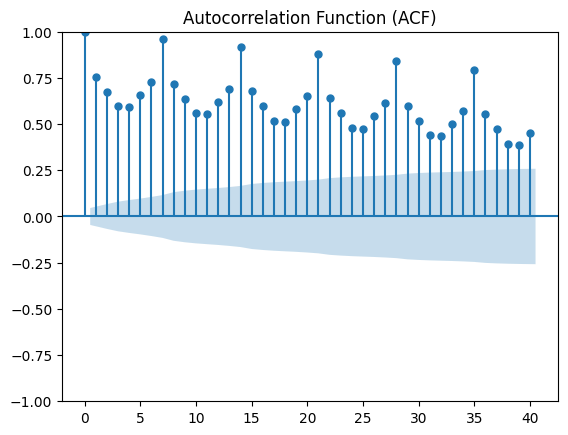

<Figure size 1200x500 with 0 Axes>

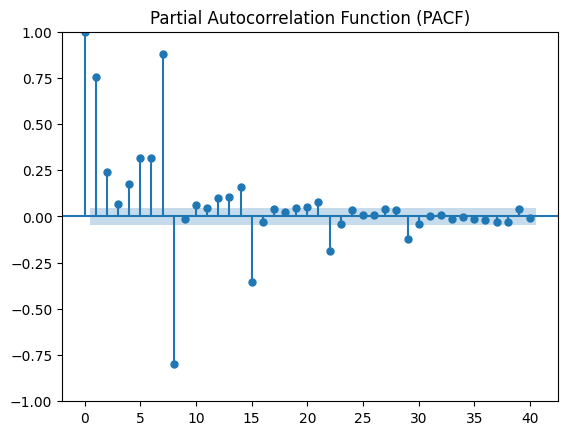

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Plot ACF
plt.figure(figsize=(12, 5))
plot_acf(target_series, lags=40, alpha=0.05)  # 40 lags, 95% confidence interval
plt.title('Autocorrelation Function (ACF)')
plt.show()

# Plot PACF
plt.figure(figsize=(12, 5))
plot_pacf(target_series, lags=40, alpha=0.05, method='ywm')  # Using Yule-Walker method
plt.title('Partial Autocorrelation Function (PACF)')
plt.show()


In [ ]:
from statsmodels.tsa.stattools import adfuller
import pandas as pd
import numpy as np

def adf_test(series, max_lag_val): # Removed default None to force explicit max_lag
    """
    Performs the Augmented Dickey-Fuller test for stationarity.
    """
    print(f"Running ADF Test with explicit maxlag={max_lag_val}")

    # Pass maxlag directly to adfuller, autolag=None is critical here
    result = adfuller(series, maxlag=max_lag_val, autolag=None)

    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {result[1]}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'   {key}: {value}')

    # Interpretation
    alpha = 0.05
    if result[1] <= alpha:
        print("Result: Series is Stationary (reject H0)")
    else:
        print("Result: Series is Non-Stationary (fail to reject H0)")
    return result

print("\n--- ADF Test on Daily Quantity Sold ---")

# Try a very small, fixed maxlag first
# For a series of ~900k points, 30 or 60 lags is still a very small fraction of the series length
# but will drastically reduce the memory footprint.
try_maxlag = 96 # Or 60, or even 10 if you're desperate

print(f"Attempting ADF test with maxlag: {try_maxlag}")
print(adf_test(target_series, max_lag_val=try_maxlag))


--- ADF Test on Daily Quantity Sold ---
Attempting ADF test with maxlag: 96
Running ADF Test with explicit maxlag=96
ADF Statistic: -3.413095012991621
p-value: 0.010520481865067021
Critical Values:
   1%: -3.434137758862471
   5%: -2.8632130839838936
   10%: -2.567660702509265
Result: Series is Stationary (reject H0)
(np.float64(-3.413095012991621), np.float64(0.010520481865067021), 96, 1729, {'1%': np.float64(-3.434137758862471), '5%': np.float64(-2.8632130839838936), '10%': np.float64(-2.567660702509265)})


In [ ]:
target_series = df_indexed['sales']

# --- Data Splitting (Time-based) ---
print("\n--- 5. Splitting Data (Time-based) ---")
train_size = int(len(target_series) * 0.95) # Use the length of the target_series

train_series_arima = target_series.iloc[:train_size]
test_series_arima = target_series.iloc[train_size:]

print(f"Training data size for ARIMA: {len(train_series_arima)} samples")
print(f"Testing data size for ARIMA: {len(test_series_arima)} samples")

# Verify types immediately after splitting
print(f"Type of train_series_arima: {type(train_series_arima)}")
print(f"Type of test_series_arima: {type(test_series_arima)}")
print(f"Index of train_series_arima is DatetimeIndex: {isinstance(train_series_arima.index, pd.DatetimeIndex)}")
print(f"Index of test_series_arima is DatetimeIndex: {isinstance(test_series_arima.index, pd.DatetimeIndex)}")


# --- Rest of your SARIMAX Rolling Forecast Code ---
from statsmodels.tsa.statespace.sarimax import SARIMAX

arima_order = (5, 1, 0)
seasonal_order = (1, 1, 0, 7) # Adjust 's' based on your data's seasonality

print("\n--- SARIMAX Rolling Forecast (Windowed History) ---")

rolling_window_size = 5000 # Adjust this based on your memory/performance

# Initialize history with the last 'rolling_window_size' points of the training series
if len(train_series_arima) < rolling_window_size:
    # If train_series_arima is a Pandas Series with DatetimeIndex, .tolist() is good
    history_sarimax_rolling = train_series_arima.tolist()
else:
    # If train_series_arima is a Pandas Series with DatetimeIndex, .iloc then .tolist() is good
    history_sarimax_rolling = train_series_arima.iloc[-rolling_window_size:].tolist()

predictions_sarimax_original_scale = list()
print_every_n_steps = 10 # Keep this to reduce output size




--- 5. Splitting Data (Time-based) ---
Training data size for ARIMA: 1734 samples
Testing data size for ARIMA: 92 samples
Type of train_series_arima: <class 'pandas.core.series.Series'>
Type of test_series_arima: <class 'pandas.core.series.Series'>
Index of train_series_arima is DatetimeIndex: True
Index of test_series_arima is DatetimeIndex: True

--- SARIMAX Rolling Forecast (Windowed History) ---


In [ ]:
for t in range(len(test_series_arima)):
    try:
        model_sarimax = SARIMAX(history_sarimax_rolling,
                                order=arima_order,
                                seasonal_order=seasonal_order,
                                enforce_stationarity=False,
                                enforce_invertibility=False)

        model_fit_sarimax = model_sarimax.fit(disp=False)

        forecast_object = model_fit_sarimax.get_prediction(start=len(history_sarimax_rolling),
                                                         end=len(history_sarimax_rolling))


        # Get the predicted mean. It can be a Series, a numpy array, or a scalar.
        predicted_mean_value = forecast_object.predicted_mean

        # Convert to a scalar if it's an array or series
        if isinstance(predicted_mean_value, (pd.Series, np.ndarray)):
            yhat_forecast = predicted_mean_value.item() # .item() extracts scalar from 0-d array/single-element array
        else:
            yhat_forecast = predicted_mean_value # It's already a scalar

        predictions_sarimax_original_scale.append(yhat_forecast)

        obs_actual = test_series_arima.iloc[t] # This should now definitely work
        history_sarimax_rolling.append(obs_actual)
        if len(history_sarimax_rolling) > rolling_window_size:
            history_sarimax_rolling.pop(0) # Remove the oldest element

        if t % print_every_n_steps == 0 or t == len(test_series_arima) - 1:
            print(f'Test Series Point: {t}\tPredicted={yhat_forecast:.2f}, Expected={obs_actual:.2f}')

    except Exception as e:
        print(f"Error during SARIMAX forecasting at step {t}: {e}")
        predictions_sarimax_original_scale.append(np.nan)
        pass

predictions_sarimax_original_scale = np.array(predictions_sarimax_original_scale)

print("\nSARIMAX Rolling Forecast Completed.")
print(f"Total predictions made: {len(predictions_sarimax_original_scale)}")
print(f"Number of printed updates: {len(test_series_arima) // print_every_n_steps + 1}")

Test Series Point: 0	Predicted=36573.14, Expected=33845.00
Test Series Point: 10	Predicted=26637.98, Expected=26899.00
Test Series Point: 20	Predicted=32652.58, Expected=32690.00
Test Series Point: 30	Predicted=26373.57, Expected=26550.00
Test Series Point: 40	Predicted=32798.53, Expected=32846.00
Test Series Point: 50	Predicted=24323.27, Expected=24636.00
Test Series Point: 60	Predicted=31084.81, Expected=30819.00
Test Series Point: 70	Predicted=26806.92, Expected=26402.00
Test Series Point: 80	Predicted=20878.47, Expected=20545.00
Test Series Point: 90	Predicted=24820.28, Expected=24988.00
Test Series Point: 91	Predicted=26266.63, Expected=26420.00

SARIMAX Rolling Forecast Completed.
Total predictions made: 92
Number of printed updates: 10


In [ ]:
if np.isnan(predictions_sarimax_original_scale).any():
    print(f"Warning: {np.sum(np.isnan(predictions_sarimax_original_scale))} NaN predictions found in ARIMA output. Filling with mean of valid predictions.")
    mean_valid_pred_arima_sales = np.nanmean(predictions_sarimax_original_scale)
    predictions_arima_original_scale_sales[np.isnan(predictions_sarimax_original_scale)] = mean_valid_pred_arima_sales

predictions_sarimax_original_scale[predictions_sarimax_original_scale < 0] = 0 # Ensure non-negative sales predictions

actual_test_series_for_eval_sales = obs_actual


In [ ]:
actual_test_series_for_eval_sales = test_series_arima.values
valid_indices = ~np.isnan(predictions_sarimax_original_scale)
predictions_for_eval = predictions_sarimax_original_scale[valid_indices]
actuals_for_eval = actual_test_series_for_eval_sales[valid_indices]


# Check lengths before calculating
if len(predictions_for_eval) != len(actuals_for_eval):
    print(f"Warning: Mismatch in lengths for evaluation! Predictions: {len(predictions_for_eval)}, Actuals: {len(actuals_for_eval)}")
    # Handle this more robustly if needed, e.g., by truncating or padding
    # For now, let's assume valid_indices makes them match.


error_mse_arima_sales = np.sqrt(mse(actuals_for_eval, predictions_for_eval))
print('ARIMA Testing Root Mean Squared Error (RMSE): %.3f' % error_mse_arima_sales)

error_smape_arima_sales = smape_kun(actuals_for_eval, predictions_for_eval)
print('ARIMA Symmetric Mean Absolute Percentage Error (SMAPE): %.3f' % error_smape_arima_sales)

# Creating Pandas Series for plotting (ensure correct series names for your plots)
# You were trying to use predictions_arima_original_scale_sales which wasn't defined
arima_actual_sales_series = pd.Series(actual_test_series_for_eval_sales, index=test_series_arima.index)
arima_predictions_sales_series = pd.Series(predictions_sarimax_original_scale, index=test_series_arima.index) # Use SARIMAX predictions

ARIMA Testing Root Mean Squared Error (RMSE): 1361.791
ARIMA Symmetric Mean Absolute Percentage Error (SMAPE): 2.554


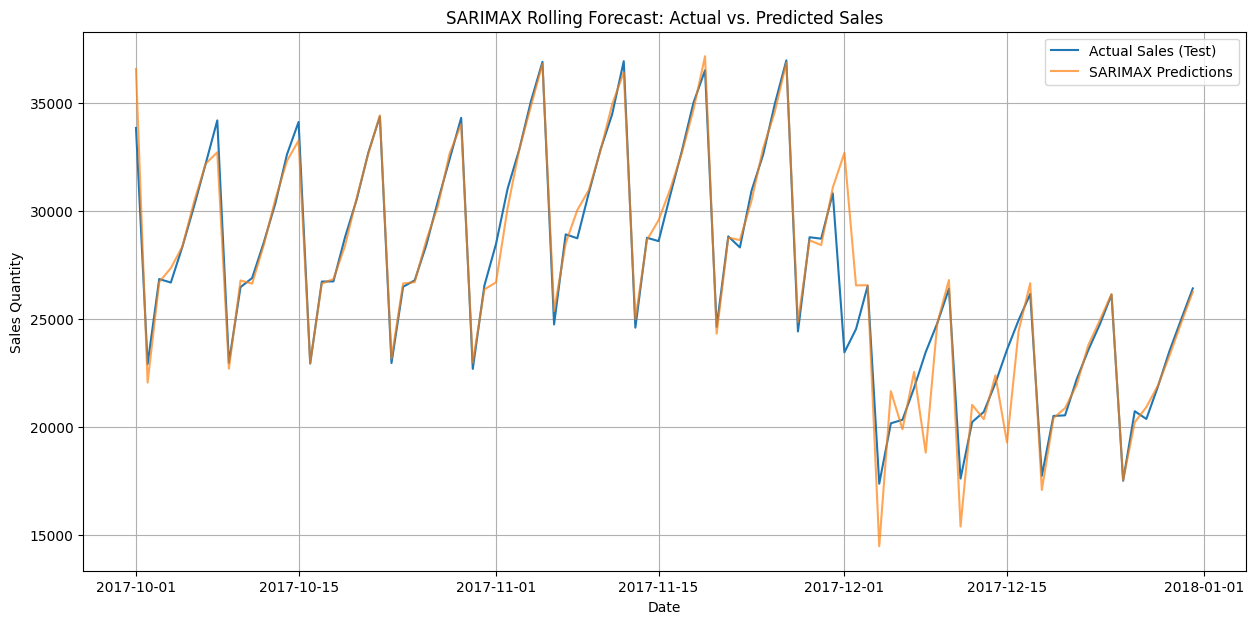

In [ ]:

plt.figure(figsize=(15, 7))
plt.plot(arima_actual_sales_series, label='Actual Sales (Test)')
plt.plot(arima_predictions_sales_series, label='SARIMAX Predictions', alpha=0.7)
plt.title('SARIMAX Rolling Forecast: Actual vs. Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Sales Quantity')
plt.legend()
plt.grid(True)
plt.show()


--- Visualizing ARIMA Forecast Results for Inventory Sales ---


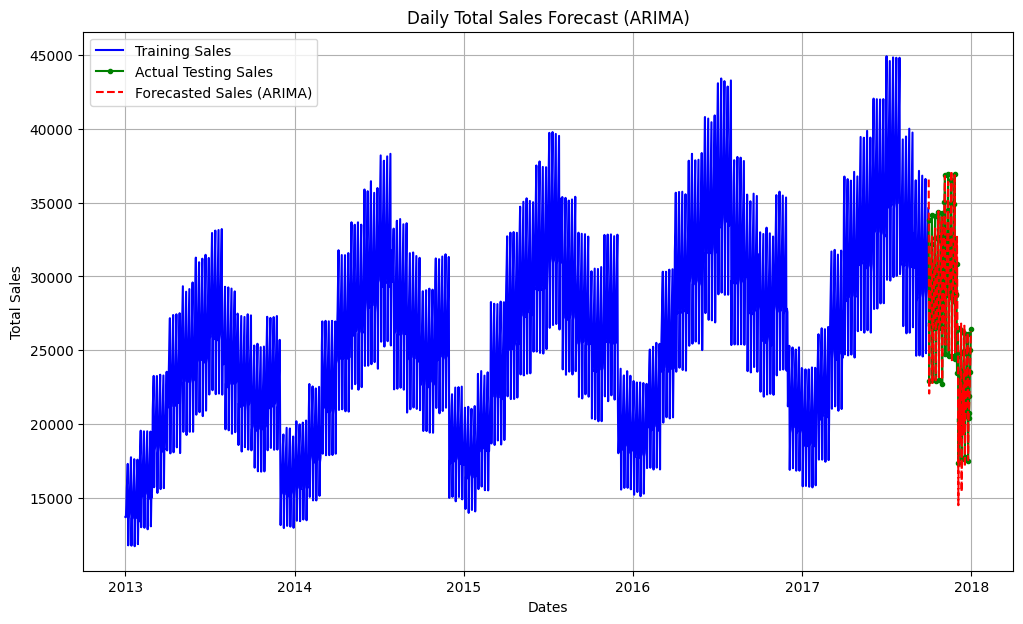

In [ ]:
print("\n--- Visualizing ARIMA Forecast Results for Inventory Sales ---")
plt.figure(figsize=(12,7))
plt.title('Daily Total Sales Forecast (ARIMA)')
plt.xlabel('Dates')
plt.ylabel('Total Sales')
plt.plot(train_series_arima, color='blue', label='Training Sales')
plt.plot(arima_actual_sales_series, color='green', marker='.', label='Actual Testing Sales')
plt.plot(arima_predictions_sales_series, color='red', linestyle='--', label='Forecasted Sales (ARIMA)')
plt.legend();
plt.grid(True)
plt.show()


--- Visualizing ARIMA Forecast Results for Inventory Sales ---


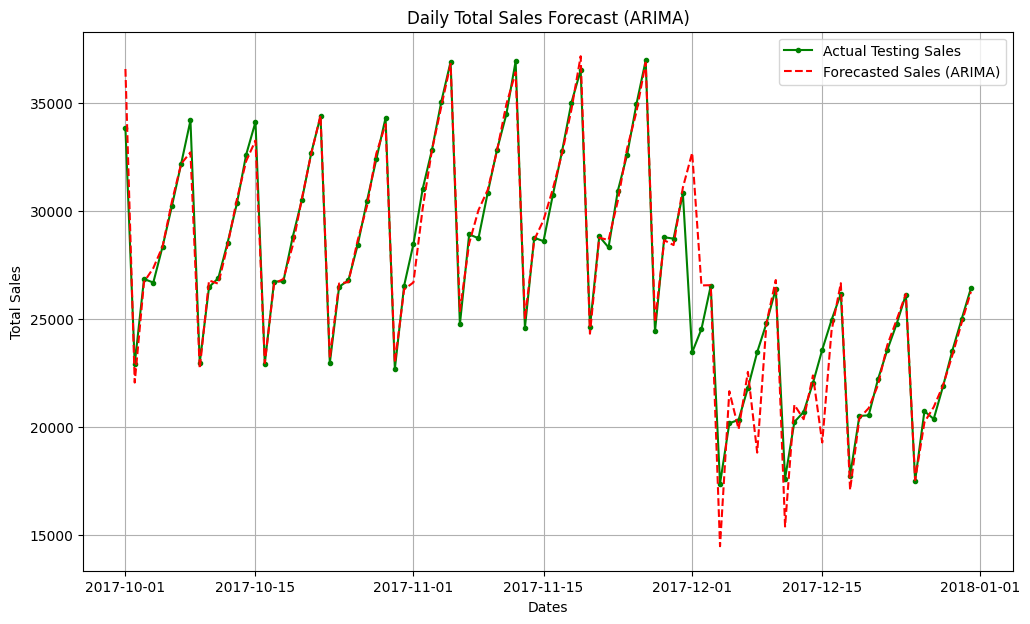

In [ ]:
print("\n--- Visualizing ARIMA Forecast Results for Inventory Sales ---")
plt.figure(figsize=(12,7))
plt.title('Daily Total Sales Forecast (ARIMA)')
plt.xlabel('Dates')
plt.ylabel('Total Sales')

plt.plot(arima_actual_sales_series, color='green', marker='.', label='Actual Testing Sales')
plt.plot(arima_predictions_sales_series, color='red', linestyle='--', label='Forecasted Sales (ARIMA)')
plt.legend();
plt.grid(True)
plt.show()

In [ ]:
predictions_sarimax_original_scale = list()
print_every_n_steps = 10 # Keep this to reduce output size
for t in range(len(test_series_arima)):
    try:
        model_sarimax = SARIMAX(history_sarimax_rolling,
                                order=(2,0,0),
                                seasonal_order=seasonal_order,
                                enforce_stationarity=False,
                                enforce_invertibility=False)

        model_fit_sarimax = model_sarimax.fit(disp=False)

        forecast_object = model_fit_sarimax.get_prediction(start=len(history_sarimax_rolling),
                                                         end=len(history_sarimax_rolling))


        predicted_mean_value = forecast_object.predicted_mean

        # Convert to a scalar if it's an array or series
        if isinstance(predicted_mean_value, (pd.Series, np.ndarray)):
            yhat_forecast = predicted_mean_value.item() # .item() extracts scalar from 0-d array/single-element array
        else:
            yhat_forecast = predicted_mean_value # It's already a scalar

        predictions_sarimax_original_scale.append(yhat_forecast)

        obs_actual = test_series_arima.iloc[t] # This should now definitely work
        history_sarimax_rolling.append(obs_actual)
        if len(history_sarimax_rolling) > rolling_window_size:
            history_sarimax_rolling.pop(0) # Remove the oldest element

        if t % print_every_n_steps == 0 or t == len(test_series_arima) - 1:
            print(f'Test Series Point: {t}\tPredicted={yhat_forecast:.2f}, Expected={obs_actual:.2f}')

    except Exception as e:
        print(f"Error during SARIMAX forecasting at step {t}: {e}")
        predictions_sarimax_original_scale.append(np.nan)
        pass

predictions_sarimax_original_scale = np.array(predictions_sarimax_original_scale)

print("\nSARIMAX Rolling Forecast Completed.")
print(f"Total predictions made: {len(predictions_sarimax_original_scale)}")
print(f"Number of printed updates: {len(test_series_arima) // print_every_n_steps + 1}")

Test Series Point: 0	Predicted=17832.21, Expected=33845.00
Test Series Point: 10	Predicted=26415.43, Expected=26899.00
Test Series Point: 20	Predicted=32669.65, Expected=32690.00
Test Series Point: 30	Predicted=26419.53, Expected=26550.00
Test Series Point: 40	Predicted=32661.34, Expected=32846.00
Test Series Point: 50	Predicted=24457.96, Expected=24636.00
Test Series Point: 60	Predicted=31049.93, Expected=30819.00
Test Series Point: 70	Predicted=27362.23, Expected=26402.00
Test Series Point: 80	Predicted=20812.05, Expected=20545.00
Test Series Point: 90	Predicted=24758.15, Expected=24988.00
Test Series Point: 91	Predicted=26239.61, Expected=26420.00

SARIMAX Rolling Forecast Completed.
Total predictions made: 92
Number of printed updates: 10


ARIMA Testing Root Mean Squared Error (RMSE): 2444.641
ARIMA Symmetric Mean Absolute Percentage Error (SMAPE): 3.947


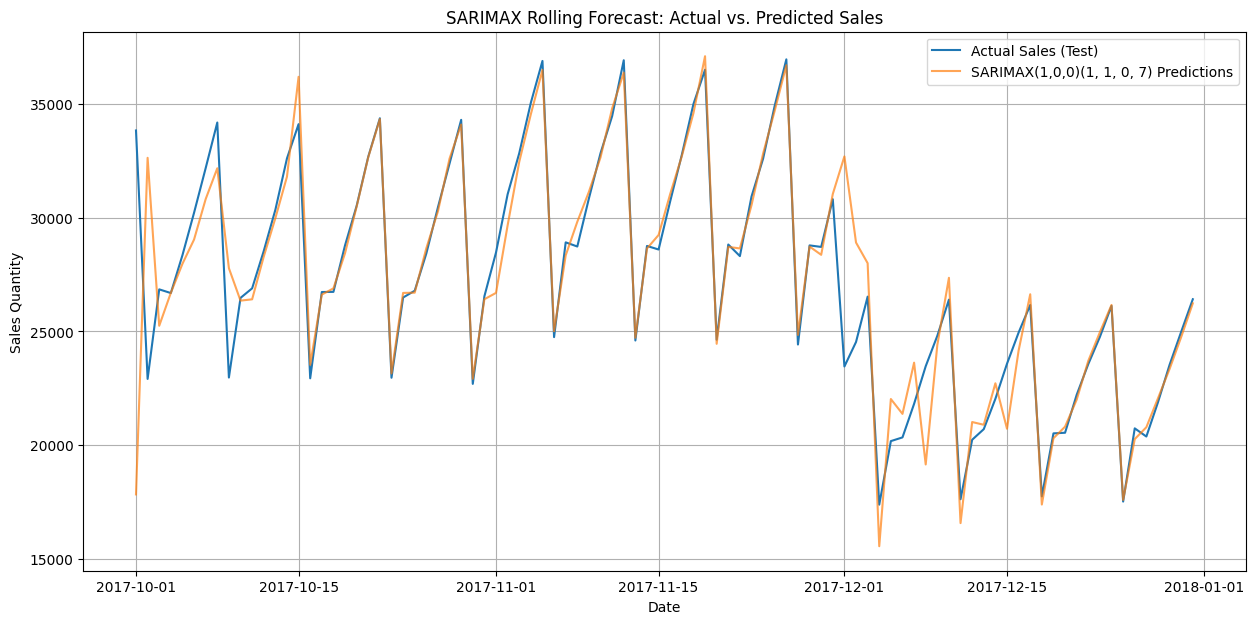

In [ ]:
if np.isnan(predictions_sarimax_original_scale).any():
    print(f"Warning: {np.sum(np.isnan(predictions_sarimax_original_scale))} NaN predictions found in ARIMA output. Filling with mean of valid predictions.")
    mean_valid_pred_arima_sales = np.nanmean(predictions_sarimax_original_scale)
    predictions_arima_original_scale_sales[np.isnan(predictions_sarimax_original_scale)] = mean_valid_pred_arima_sales

predictions_sarimax_original_scale[predictions_sarimax_original_scale < 0] = 0 # Ensure non-negative sales predictions

actual_test_series_for_eval_sales = obs_actual
actual_test_series_for_eval_sales = test_series_arima.values
valid_indices = ~np.isnan(predictions_sarimax_original_scale)
predictions_for_eval = predictions_sarimax_original_scale[valid_indices]
actuals_for_eval = actual_test_series_for_eval_sales[valid_indices]


# Check lengths before calculating
if len(predictions_for_eval) != len(actuals_for_eval):
    print(f"Warning: Mismatch in lengths for evaluation! Predictions: {len(predictions_for_eval)}, Actuals: {len(actuals_for_eval)}")
    # Handle this more robustly if needed, e.g., by truncating or padding
    # For now, let's assume valid_indices makes them match.


error_mse_arima_sales = np.sqrt(mse(actuals_for_eval, predictions_for_eval))
print('ARIMA Testing Root Mean Squared Error (RMSE): %.3f' % error_mse_arima_sales)

error_smape_arima_sales = smape_kun(actuals_for_eval, predictions_for_eval)
print('ARIMA Symmetric Mean Absolute Percentage Error (SMAPE): %.3f' % error_smape_arima_sales)

# Creating Pandas Series for plotting (ensure correct series names for your plots)
# You were trying to use predictions_arima_original_scale_sales which wasn't defined
arima_actual_sales_series = pd.Series(actual_test_series_for_eval_sales, index=test_series_arima.index)
arima_predictions_sales_series = pd.Series(predictions_sarimax_original_scale, index=test_series_arima.index) # Use SARIMAX predictions

plt.figure(figsize=(15, 7))
plt.plot(arima_actual_sales_series, label='Actual Sales (Test)')
plt.plot(arima_predictions_sales_series, label='SARIMAX(1,0,0)(1, 1, 0, 7) Predictions', alpha=0.7)
plt.title('SARIMAX Rolling Forecast: Actual vs. Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Sales Quantity')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Aggregate sales by date index by summing
sales_aggregated = df.groupby(df.index)['sales'].sum().reset_index()

print(sales_aggregated.head())


        date  sales
0 2013-01-01  13696
1 2013-01-02  13678
2 2013-01-03  14488
3 2013-01-04  15677
4 2013-01-05  16237


In [ ]:
import numpy as np
import xgboost as xgb
import pandas as pd

# Step 1: Set the date column as datetime index
sales_aggregated['date'] = pd.to_datetime(sales_aggregated['date'])
sales_aggregated.set_index('date', inplace=True)



In [ ]:
# Step 2: Extract date features from the index
def extract_date_features(df):
    df = df.copy()
    df['year'] = df.index.year
    df['month'] = df.index.month
    df['day'] = df.index.day
    df['dayofweek'] = df.index.dayofweek
    df['dayofyear'] = df.index.dayofyear
    df['weekofyear'] = df.index.isocalendar().week.astype(int)
    return df

features_date = extract_date_features(sales_aggregated)

# Step 3: Prepare target and features
target_series = sales_aggregated['sales']
features = features_date.drop(columns=['sales'])  # only date features used

# Step 4: Train/test split (95% train)
train_size = int(len(target_series) * 0.95)
X_train = features.iloc[:train_size]
y_train = target_series.iloc[:train_size]
X_test = features.iloc[train_size:]
y_test = target_series.iloc[train_size:]

# Rolling forecast parameters
rolling_window_size = 5000
print_every_n_steps = 10

# Initialize rolling history
if len(X_train) < rolling_window_size:
    history_features = X_train.copy()
    history_targets = y_train.tolist()
else:
    history_features = X_train.iloc[-rolling_window_size:].copy()
    history_targets = y_train.iloc[-rolling_window_size:].tolist()

predictions_xgb = []

# Rolling forecast with XGBoost
for t in range(len(X_test)):
    try:
        model = xgb.XGBRegressor(
            n_estimators=100,

            random_state=42
        )


        model.fit(history_features, history_targets)

        X_test_row = X_test.iloc[[t]]
        yhat = model.predict(X_test_row)[0]
        predictions_xgb.append(yhat)

        y_true = y_test.iloc[t]
        history_targets.append(y_true)
        history_features = pd.concat([history_features, X_test_row])

        if len(history_features) > rolling_window_size:
            history_features = history_features.iloc[1:]
            history_targets.pop(0)

        if t % print_every_n_steps == 0 or t == len(X_test) - 1:
            print(f'Test Point {t}: Predicted={yhat:.2f}, Actual={y_true:.2f}')

    except Exception as e:
        print(f'Error at step {t}: {e}')
        predictions_xgb.append(np.nan)

predictions_xgb = np.array(predictions_xgb)

print("\nXGBoost Rolling Forecast Completed.")
print(f"Total predictions made: {len(predictions_xgb)}")
print(f"Number of printed updates: {len(X_test) // print_every_n_steps + 1}")


Test Point 0: Predicted=34511.57, Actual=33845.00
Test Point 10: Predicted=26477.68, Actual=26899.00
Test Point 20: Predicted=32856.38, Actual=32690.00
Test Point 30: Predicted=26614.91, Actual=26550.00
Test Point 40: Predicted=33044.33, Actual=32846.00
Test Point 50: Predicted=24604.17, Actual=24636.00
Test Point 60: Predicted=30759.59, Actual=30819.00
Test Point 70: Predicted=26367.46, Actual=26402.00
Test Point 80: Predicted=20518.84, Actual=20545.00
Test Point 90: Predicted=24686.56, Actual=24988.00
Test Point 91: Predicted=26030.89, Actual=26420.00

XGBoost Rolling Forecast Completed.
Total predictions made: 92
Number of printed updates: 10


In [ ]:
if np.isnan(predictions_xgb).any():
    num_nans = np.sum(np.isnan(predictions_xgb))
    print(f"Warning: {num_nans} NaN predictions found in XGB output. Filling with mean of valid predictions.")

    mean_valid_pred_xgb = np.nanmean(predictions_xgb)
    predictions_xgb[np.isnan(predictions_xgb)] = mean_valid_pred_xgb

# Ensure sales predictions are non-negative
predictions_xgb[predictions_xgb < 0] = 0

# For actual sales to use in evaluation, use original test series values
actual_test_series_for_eval_sales = y_test.values

XGBoost Testing Root Mean Squared Error (RMSE): 437.121
XGBoost Symmetric Mean Absolute Percentage Error (SMAPE): 1.144


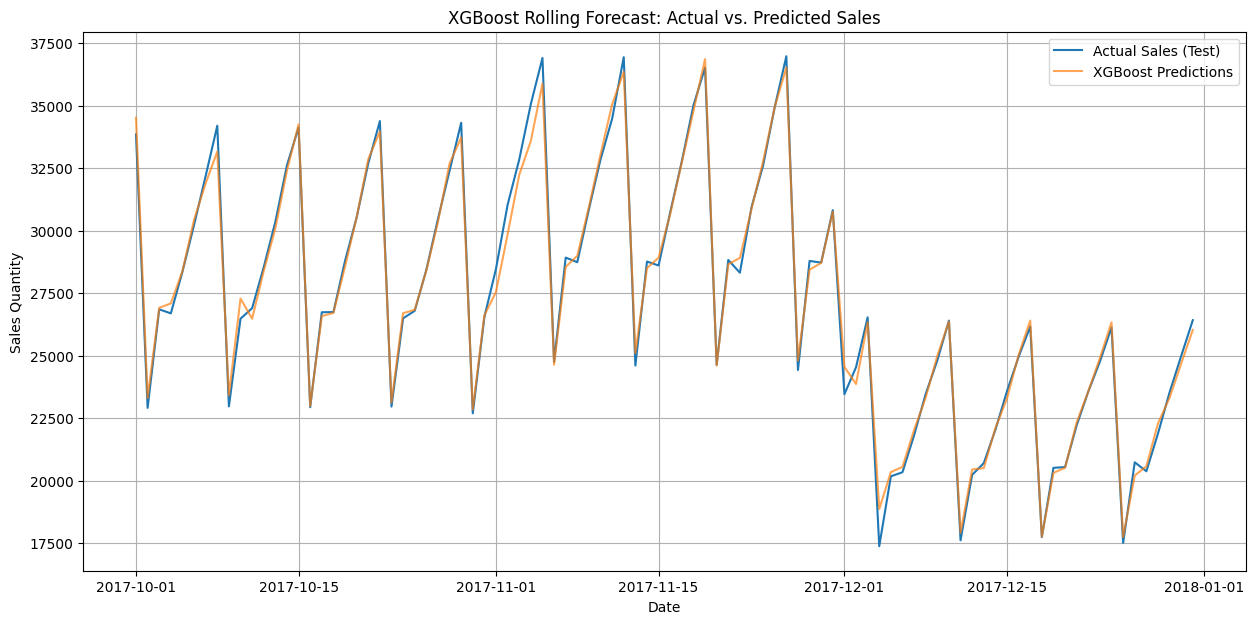

In [ ]:


#  Handle NaN predictions (already done previously, but check again)
valid_indices_xgb = ~np.isnan(predictions_xgb)
predictions_for_eval_xgb = predictions_xgb[valid_indices_xgb]
actuals_for_eval_xgb = actual_test_series_for_eval_sales[valid_indices_xgb]

#  Check lengths
if len(predictions_for_eval_xgb) != len(actuals_for_eval_xgb):
    print(f"Warning: Mismatch in lengths for XGB evaluation! Predictions: {len(predictions_for_eval_xgb)}, Actuals: {len(actuals_for_eval_xgb)}")
    # You could truncate/pad arrays here if necessary

#  Calculate RMSE and SMAPE errors
error_rmse_xgb = np.sqrt(mse(actuals_for_eval_xgb, predictions_for_eval_xgb))
print(f'XGBoost Testing Root Mean Squared Error (RMSE): {error_rmse_xgb:.3f}')

error_smape_xgb = smape_kun(actuals_for_eval_xgb, predictions_for_eval_xgb)
print(f'XGBoost Symmetric Mean Absolute Percentage Error (SMAPE): {error_smape_xgb:.3f}')


#  Create Pandas Series for plotting with correct datetime index
xgb_actual_sales_series = pd.Series(actual_test_series_for_eval_sales, index=y_test.index)
xgb_predictions_sales_series = pd.Series(predictions_xgb, index=y_test.index)

#  Plot actual vs predicted sales for XGBoost
plt.figure(figsize=(15,7))
plt.plot(xgb_actual_sales_series, label='Actual Sales (Test)')
plt.plot(xgb_predictions_sales_series, label='XGBoost Predictions', alpha=0.7)
plt.title('XGBoost Rolling Forecast: Actual vs. Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Sales Quantity')
plt.legend()
plt.grid(True)
plt.show()


--- Visualizing XGBoost Forecast Results for Inventory Sales ---


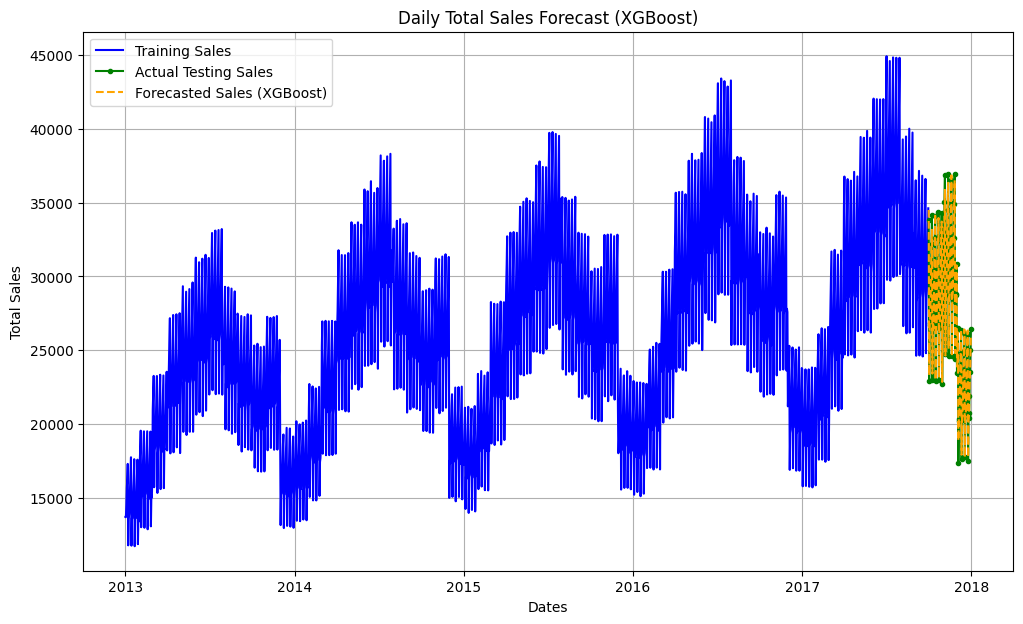

In [ ]:

print("\n--- Visualizing XGBoost Forecast Results for Inventory Sales ---")

plt.figure(figsize=(12,7))
plt.title('Daily Total Sales Forecast (XGBoost)')
plt.xlabel('Dates')
plt.ylabel('Total Sales')

# Plot training sales (same as your ARIMA training series)
plt.plot(train_series_arima, color='blue', label='Training Sales')

# Plot actual test sales
plt.plot(xgb_actual_sales_series, color='green', marker='.', label='Actual Testing Sales')

# Plot XGBoost forecast sales
plt.plot(xgb_predictions_sales_series, color='orange', linestyle='--', label='Forecasted Sales (XGBoost)')

plt.legend()
plt.grid(True)
plt.show()



--- Visualizing XGBoost Forecast Results for Inventory Sales ---


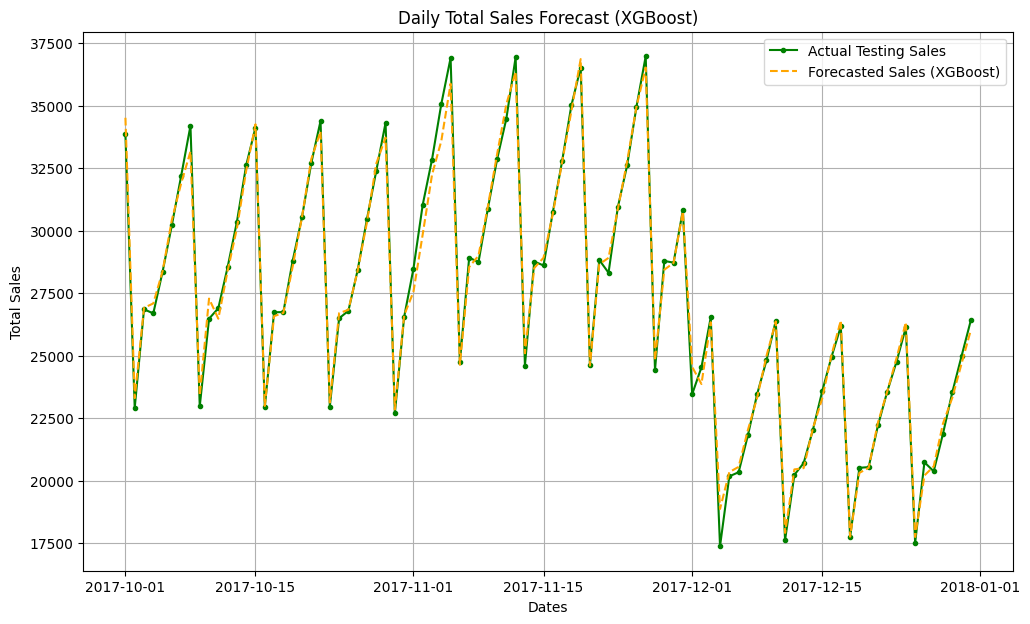

In [ ]:
print("\n--- Visualizing XGBoost Forecast Results for Inventory Sales ---")
plt.figure(figsize=(12,7))
plt.title('Daily Total Sales Forecast (XGBoost)')
plt.xlabel('Dates')
plt.ylabel('Total Sales')

plt.plot(xgb_actual_sales_series, color='green', marker='.', label='Actual Testing Sales')
plt.plot(xgb_predictions_sales_series, color='orange', linestyle='--', label='Forecasted Sales (XGBoost)')

plt.legend()
plt.grid(True)
plt.show()



--- Comparing Forecasts: ARIMA vs XGBoost ---


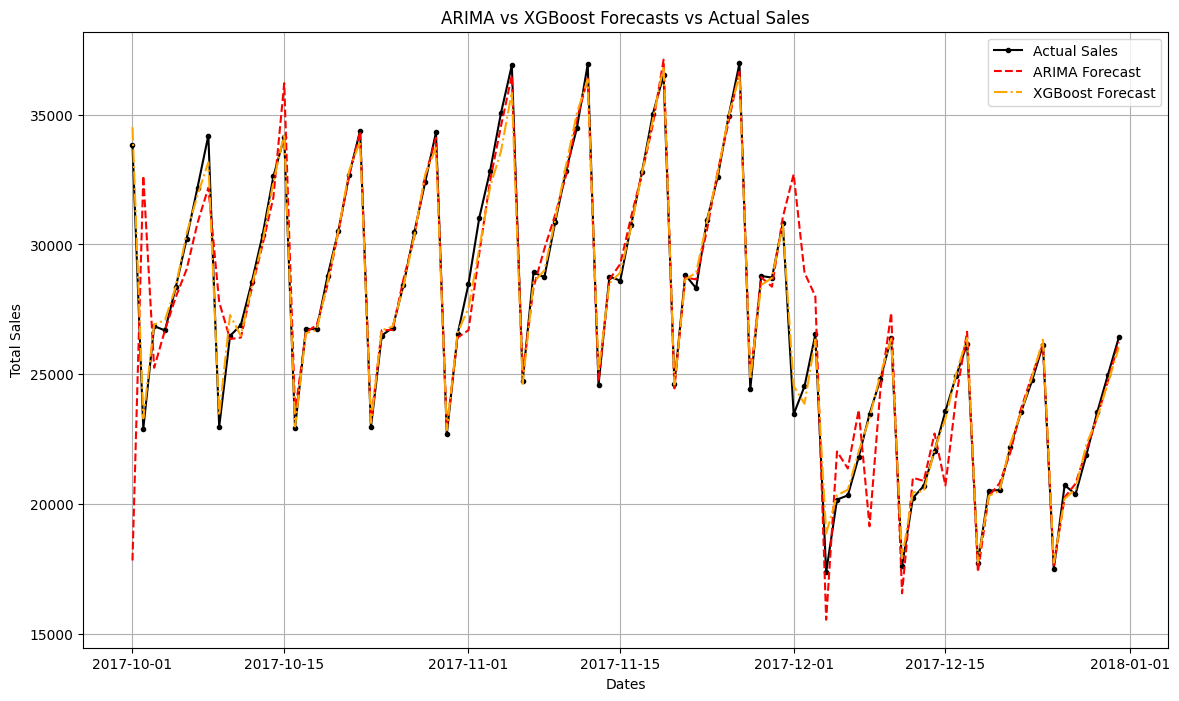

In [ ]:
# Combined plot: ARIMA vs XGBoost vs Actual
print("\n--- Comparing Forecasts: ARIMA vs XGBoost ---")
plt.figure(figsize=(14,8))
plt.title('ARIMA vs XGBoost Forecasts vs Actual Sales')
plt.xlabel('Dates')
plt.ylabel('Total Sales')

plt.plot(arima_actual_sales_series, color='black', marker='.', label='Actual Sales')
plt.plot(arima_predictions_sales_series, color='red', linestyle='--', label='ARIMA Forecast')
plt.plot(xgb_predictions_sales_series, color='orange', linestyle='-.', label='XGBoost Forecast')

plt.legend()
plt.grid(True)
plt.show()

# Inventory Sales Forecasting Model Comparison

The performance of XGBoost and ARIMA models on daily total sales forecasting is summarized below.

| Metric | XGBoost | ARIMA |
|--------|---------|-------|
| **Root Mean Squared Error (RMSE)** | 437.121 | 2444.641 |
| **Symmetric Mean Absolute Percentage Error (SMAPE)** | 1.144 | 3.947 |

---

### Key Insights

- **Accuracy:** XGBoost significantly outperforms ARIMA, achieving much lower RMSE and SMAPE values. This means XGBoost's predictions are closer to actual sales values.
- **Robustness:** The lower SMAPE suggests XGBoost handles variations in sales magnitude better across the dataset.
- **Visual Fit:** XGBoost forecast lines closely track the actual sales trends, while ARIMA shows noticeable deviations, especially during volatile periods.

---

### Conclusion

XGBoost is the preferred forecasting model for this inventory sales data, offering superior accuracy and reliability compared to ARIMA. It is well-suited for capturing complex patterns and seasonality in sales data, aiding better inventory management and decision-making.


## Using LSTM



--- 9. Time Series Forecasting with Deep Learning (LSTM for Inventory Sales) ---
This section forecasts 'sales' using LSTM networks on the aggregated daily total sales.
LSTM Training series shape: (1460,)
LSTM Test series shape: (366,)


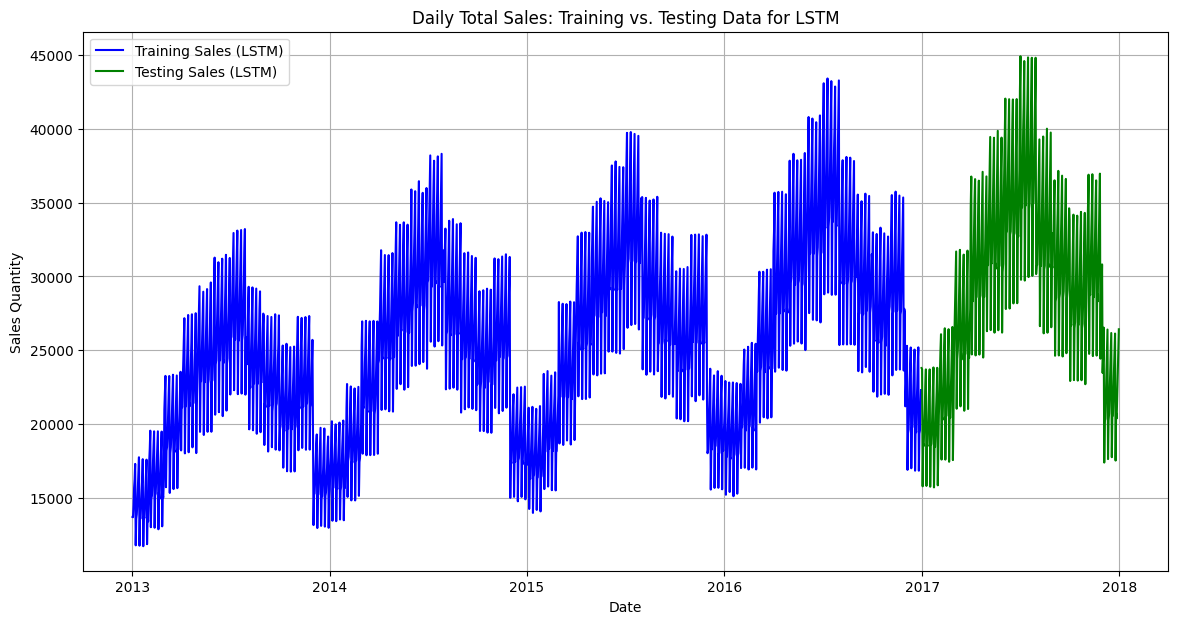

In [ ]:
print("\n\n--- 9. Time Series Forecasting with Deep Learning (LSTM for Inventory Sales) ---")
print("This section forecasts 'sales' using LSTM networks on the aggregated daily total sales.")

train_data_lstm_sales = df_indexed_aggregated.iloc[:int(len(df_indexed_aggregated)*0.8)]
test_data_lstm_sales = df_indexed_aggregated.iloc[int(len(df_indexed_aggregated)*0.8):]

train_series_lstm_sales = train_data_lstm_sales['sales']
test_series_lstm_sales = test_data_lstm_sales['sales']

print(f"LSTM Training series shape: {train_series_lstm_sales.shape}")
print(f"LSTM Test series shape: {test_series_lstm_sales.shape}")

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))
plt.plot(train_series_lstm_sales.index.to_numpy(), train_series_lstm_sales.to_numpy(), color='blue', label='Training Sales (LSTM)')
plt.plot(test_series_lstm_sales.index.to_numpy(), test_series_lstm_sales.to_numpy(), color='green', label='Testing Sales (LSTM)')
plt.title('Daily Total Sales: Training vs. Testing Data for LSTM')
plt.xlabel('Date')
plt.ylabel('Sales Quantity')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
sc_lstm = MinMaxScaler(feature_range=(0,1))


training_set_scaled_lstm = sc_lstm.fit_transform(train_series_lstm_sales.values.reshape(-1, 1))
print(f"\nScaled training set shape for LSTM: {training_set_scaled_lstm.shape}")

# --- Train Data Preparation (Sliding Window) ---
X_train_lstm = []
y_train_lstm = []
window_size_lstm = 60 # Using 60 days as sliding window
for i in range(window_size_lstm, len(training_set_scaled_lstm)):
    X_train_lstm.append(training_set_scaled_lstm[i-window_size_lstm:i, 0])
    y_train_lstm.append(training_set_scaled_lstm[i, 0])
X_train_lstm, y_train_lstm = np.array(X_train_lstm), np.array(y_train_lstm)
print(f"\nX_train_lstm shape before reshape: {X_train_lstm.shape}, y_train_lstm shape: {y_train_lstm.shape}")

# Reshape X_train for LSTM input: (batch_size, timesteps, input_dim)
X_train_lstm = np.reshape(X_train_lstm, (X_train_lstm.shape[0], X_train_lstm.shape[1], 1))
print(f"X_train_lstm shape after reshape: {X_train_lstm.shape}")



Scaled training set shape for LSTM: (1460, 1)

X_train_lstm shape before reshape: (1400, 60), y_train_lstm shape: (1400,)
X_train_lstm shape after reshape: (1400, 60, 1)


In [ ]:
# --- LSTM Regression model ---
print("\n--- Building LSTM Model Architecture for Sales Forecasting ---")
regressor_lstm = Sequential()

regressor_lstm.add(LSTM(units=64, return_sequences=True, input_shape=(X_train_lstm.shape[1], 1)))
regressor_lstm.add(Dropout(0.2))

regressor_lstm.add(LSTM(units=64, return_sequences=False))
regressor_lstm.add(Dropout(0.2))

regressor_lstm.add(Dense(units=1))

regressor_lstm.compile(optimizer=SGD(learning_rate=0.01, momentum=0.9), loss='mean_squared_error')
regressor_lstm.summary()



--- Building LSTM Model Architecture for Sales Forecasting ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,985 (195.25 KB)

 Trainable params: 49,985 (195.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = regressor_lstm.fit(
    X_train_lstm, y_train_lstm,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 61ms/step - loss: 0.0750 - val_loss: 0.0353
Epoch 2/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - loss: 0.0254 - val_loss: 0.0175
Epoch 3/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - loss: 0.0170 - val_loss: 0.0163
Epoch 4/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - loss: 0.0158 - val_loss: 0.0166
Epoch 5/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.0141 - val_loss: 0.0165
Epoch 6/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.0148 - val_loss: 0.0171
Epoch 7/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - loss: 0.0139 - val_loss: 0.0163
Epoch 8/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - loss: 0.0149 - val_loss: 0.0160
Epoch 9/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - loss: 0.0144 - val_loss: 0.0160
Epoch 10/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - loss: 0.0140 - val_loss: 0.0159
Epoch 11/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.0143 - val_loss: 0.0176
Epoch 12/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.0

In [ ]:
# Scale test data using the same scaler (sc_lstm)
test_set_scaled_lstm = sc_lstm.transform(test_series_lstm_sales.values.reshape(-1,1))

# Create sliding window sequences for test data, same window_size_lstm
X_test_lstm = []
y_test_lstm = []
for i in range(window_size_lstm, len(test_set_scaled_lstm)):
    X_test_lstm.append(test_set_scaled_lstm[i-window_size_lstm:i, 0])
    y_test_lstm.append(test_set_scaled_lstm[i, 0])
X_test_lstm, y_test_lstm = np.array(X_test_lstm), np.array(y_test_lstm)

# Reshape for LSTM input
X_test_lstm = X_test_lstm.reshape((X_test_lstm.shape[0], X_test_lstm.shape[1], 1))


In [ ]:
lstm_predictions_scaled = regressor_lstm.predict(X_test_lstm)
lstm_predictions = sc_lstm.inverse_transform(lstm_predictions_scaled)
y_test_actual = sc_lstm.inverse_transform(y_test_lstm.reshape(-1,1))


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 160ms/step


In [ ]:

rmse_lstm = np.sqrt(mse(y_test_actual, lstm_predictions))
r2_lstm = r2_score(y_test_actual, lstm_predictions)

print(f"LSTM Test RMSE: {rmse_lstm:.3f}")
print(f"LSTM Test R^2: {r2_lstm:.3f}")


LSTM Test RMSE: 4394.784
LSTM Test R^2: 0.407


In [ ]:

lstm_pred_series = pd.Series(lstm_predictions.flatten(), index=test_series_lstm_sales.index[window_size_lstm:])
lstm_actual_series = test_series_lstm_sales.iloc[window_size_lstm:]


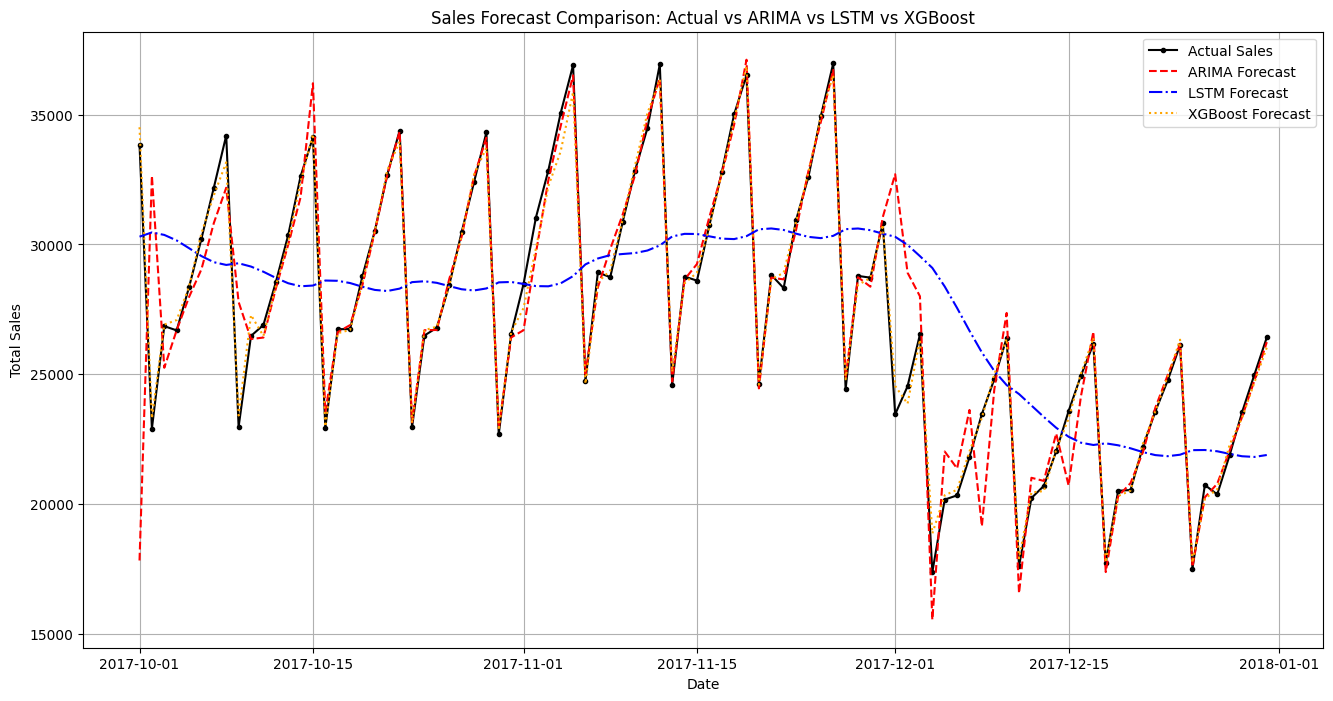

In [ ]:

common_index = arima_predictions_sales_series.index.intersection(lstm_pred_series.index).intersection(xgb_predictions_sales_series.index)

# Align all series to common index
arima_plot = arima_predictions_sales_series.loc[common_index]
lstm_plot = lstm_pred_series.loc[common_index]
xgb_plot = xgb_predictions_sales_series.loc[common_index]
actual_plot = arima_actual_sales_series.loc[common_index]  # or y_test indexed similarly

plt.figure(figsize=(16,8))
plt.plot(actual_plot, label='Actual Sales', color='black', marker='.', linestyle='-')
plt.plot(arima_plot, label='ARIMA Forecast', color='red', linestyle='--')
plt.plot(lstm_plot, label='LSTM Forecast', color='blue', linestyle='-.')
plt.plot(xgb_predictions_sales_series, label='XGBoost Forecast', color='orange', linestyle=':')

plt.title('Sales Forecast Comparison: Actual vs ARIMA vs LSTM vs XGBoost')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.legend()
plt.grid(True)
plt.show()


##  Conclusion

In this project, we explored multiple forecasting techniques — including **Machine Learning models, SARIMA, and LSTM** — to predict inventory demand.  
The results highlight that:

- **Statistical models (SARIMA/ARIMA)** captured seasonality and trends well, providing a solid baseline.  
- **Machine learning approaches** offered flexibility with engineered features but required careful tuning (XGBoost used)
- **LSTM (deep learning)** leveraged sequential dependencies, though it was computationally heavier and sometimes prone to overfitting on limited patterns.  

Overall, combining insights from different models led to improved forecasting accuracy.  
This analysis can support **better inventory planning and demand management**, reducing stock-outs and overstock situations in real-world scenarios.


---
